# AI4EVAR — Results Comparison

Loads one or more test-result folders, prints a comparison table, and plots joined ROC curves.

**Folder layouts auto-detected:**
- New canonical: `<run_root>/<split>/<stage>/test_metrics.json`
- Single-checkpoint: `<run_root>/<split>/test_metrics.json`
- Legacy flat: `<run_root>/test_metrics.json` → inferred as split=`test`, stage=`unknown`

---
**Typical workflows:**
```
Compare methods        →  RESULT_DIRS={MLP:…, TabM:…, LR:…}  FILTER_STAGE="stage_b"  FILTER_SPLIT="test"  ROC_GROUP_BY="run"
Compare stage_a vs b   →  RESULT_DIRS={TabM:…}                FILTER_STAGE=None       FILTER_SPLIT="test"  ROC_GROUP_BY="stage"
Compare train/val/test →  RESULT_DIRS={TabM:…}                FILTER_STAGE="stage_b"  FILTER_SPLIT=None    ROC_GROUP_BY="split"
Cross-ref (method×stage)→ RESULT_DIRS={MLP:…, TabM:…}         FILTER_STAGE=None       FILTER_SPLIT="test"  ROC_GROUP_BY="run+stage"
```

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_curve, auc as sklearn_auc
from IPython.display import display
import os

warnings.filterwarnings("ignore")
%matplotlib inline

# ── Global plot style ─────────────────────────────────────────────────────────
_BG      = "#F8FAFC"   # axes background (slate-50)
_GRID    = "#E2E8F0"   # grid line colour (slate-200)
_SPINE   = "#CBD5E1"   # axis spine colour (slate-300)
_TEXT    = "#1E293B"   # title / label colour (slate-800)
_SUBTEXT = "#64748B"   # tick / legend colour (slate-500)

plt.rcParams.update({
    "figure.dpi":          130,
    "figure.facecolor":    "white",
    "axes.facecolor":      _BG,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "axes.edgecolor":      _SPINE,
    "axes.linewidth":      0.9,
    "axes.grid":           True,
    "grid.color":          _GRID,
    "grid.linestyle":      "-",
    "grid.linewidth":      0.8,
    "grid.alpha":          1.0,
    "axes.labelcolor":     _TEXT,
    "axes.labelsize":      12,
    "axes.titlesize":      14,
    "axes.titleweight":    "bold",
    "axes.titlecolor":     _TEXT,
    "axes.titlepad":       14,
    "xtick.color":         _SUBTEXT,
    "ytick.color":         _SUBTEXT,
    "xtick.labelsize":     10,
    "ytick.labelsize":     10,
    "legend.framealpha":   0.96,
    "legend.edgecolor":    _SPINE,
    "legend.fontsize":     10,
    "legend.title_fontsize": 10,
    "font.family":         "sans-serif",
})

# Curated palette — distinct, colourblind-safe, ordered by visibility
_PALETTE = [
    "#2563EB",  # blue
    "#DC2626",  # red
    "#16A34A",  # green
    "#D97706",  # amber
    "#7C3AED",  # violet
    "#DB2777",  # pink
    "#0891B2",  # cyan
    "#EA580C",  # orange
    "#65A30D",  # lime
    "#475569",  # slate
]

# Pastel colormaps for the table gradients
_CMAP_AUC = LinearSegmentedColormap.from_list(
    "pastel_rdylgn", ["#FCA5A5", "#FEF08A", "#86EFAC"]
)  # pastel red → yellow → green
_CMAP_F1 = LinearSegmentedColormap.from_list(
    "pastel_blues", ["#EFF6FF", "#BAE6FD", "#7DD3FC"]
)  # near-white → pastel sky blue
_CMAP_TEAL = LinearSegmentedColormap.from_list(
    "pastel_teal", ["#F0FDFA", "#99F6E4", "#5EEAD4"]
)  # near-white → pastel teal

## 1. Configuration

**What:** Set which result folders to compare, which split/stage to focus on, and how to group ROC curves.

**How to use:**
- Add one entry per model/run to `RESULT_DIRS` — the key becomes the label in all plots and tables
- `FILTER_STAGE` / `FILTER_SPLIT` narrow down which results are loaded (e.g. only `stage_b` on `test`)
- `ROC_GROUP_BY` controls what counts as one ROC curve: one per model (`run`), per split, per stage, or combinations

Everything downstream re-runs automatically when you change this cell.

In [2]:
# ── Result roots ──────────────────────────────────────────────────────────────
# Keys become the "run" label in the table and ROC legend.
RESULT_DIRS = {
    "TabM": "/home/ranema/AI4EVAR/test_results/v1_no_complications_TabM_08062026",
    "TabPFN": "/home/ranema/AI4EVAR/test_results/v1_no_complications_TabPFN_10062026",
    "MLP":  "/home/ranema/AI4EVAR/test_results/v1_no_complications_MLP_08062026",
    "SAINT": "/home/ranema/AI4EVAR/test_results/v1_no_complications_SAINT_08062026",
    "Logistic Regression":   "/home/ranema/AI4EVAR/test_results/v1_logistic_regression_08062026",
    "Random Forest":   "/home/ranema/AI4EVAR/test_results/v1_random_forest_10062026",
    "XGBoost": "/home/ranema/AI4EVAR/test_results/v1_xgboost_10062026",
    "GradientBoosting": "/home/ranema/AI4EVAR/test_results/v1_gradient_boosting_10062026",
}

OUTPUT_DIR = "/home/ranema/AI4EVAR/test_results/plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Filters  (None = keep all) ────────────────────────────────────────────────
FILTER_STAGE = "stage_b"      # "stage_a" | "stage_b" | None
FILTER_SPLIT = "test"      # "train"   | "val"     | "test" | None

# ── ROC grouping ──────────────────────────────────────────────────────────────
# Each unique value of this key becomes one ROC curve.
#   "run"        → one curve per RESULT_DIRS entry           (compare methods)
#   "stage"      → one curve per stage (stage_a / stage_b)   (compare stages)
#   "split"      → one curve per split (train / val / test)  (compare splits)
#   "run+stage"  → one curve per (method, stage) combination
#   "run+split"  → one curve per (method, split) combination
ROC_GROUP_BY = "run"

# ── Table columns ─────────────────────────────────────────────────────────────
METRICS_TO_SHOW = [
    "auc", "best_f1", "f1", "precision", "recall",
    "accuracy", "TPR_sensitivity", "TNR_specificity",
    "n_samples", "n_positive",
]

# ── Bar chart metrics ─────────────────────────────────────────────────────────
BAR_METRICS = ["auc", "best_f1", "TPR_sensitivity", "TNR_specificity"]

FIG_SIZE = (10, 7)

## 2. Load Results

**What:** Scans each folder in `RESULT_DIRS`, finds all `test_metrics.json` files, and infers which split (train/val/test) and stage (stage_a/stage_b) each one belongs to from its folder path.

Also loads the per-patient `prediction.json` files (probability score + ground truth label per patient) — these are needed for the ROC curves and bootstrap sections later.

**Why it matters:** All subsequent sections work from what is loaded here. If a folder is missing or a filter is too narrow, the relevant sections will simply print a warning and skip.

In [3]:
_SPLIT_NAMES = {"train", "val", "test"}


def _infer_split_stage(root: Path, leaf: Path) -> tuple[str, str]:
    """Walk the path parts relative to root and pick up split / stage tokens."""
    split, stage = "test", "unknown"
    for p in leaf.relative_to(root).parts:
        if p in _SPLIT_NAMES:
            split = p
        elif p.startswith("stage_"):
            stage = p
    return split, stage


def _load_preds(leaf: Path) -> pd.DataFrame:
    """Collect every <pid>/prediction.json under leaf into a DataFrame."""
    rows = []
    for pf in sorted(leaf.glob("*/prediction.json")):
        with open(pf) as f:
            rows.append(json.load(f))
    return pd.DataFrame(rows) if rows else pd.DataFrame()


def load_all(
    result_dirs: dict,
    filter_stage: str | None = None,
    filter_split: str | None = None,
) -> tuple[pd.DataFrame, dict]:
    """
    Scan all result_dirs, auto-detect split/stage from path structure,
    apply filters, and return:
      metrics_df  — one row per (run, split, stage)
      preds       — dict[(run, split, stage)] → per-patient prediction DataFrame
    """
    metric_rows, preds = [], {}

    for run_name, root_str in result_dirs.items():
        root = Path(root_str)
        if not root.exists():
            print(f"  [WARN] {root} not found — skipping.")
            continue

        leaves = sorted(p.parent for p in root.rglob("test_metrics.json"))
        if not leaves:
            print(f"  [WARN] No test_metrics.json found under {root}")
            continue

        for leaf in leaves:
            split, stage = _infer_split_stage(root, leaf)

            if filter_split is not None and split != filter_split:
                continue
            if filter_stage is not None and stage != filter_stage:
                continue

            with open(leaf / "test_metrics.json") as f:
                m = json.load(f)

            row = {"run": run_name, "split": split, "stage": stage, **m}
            metric_rows.append(row)
            preds[(run_name, split, stage)] = _load_preds(leaf)

    if not metric_rows:
        print("No results match the current filters.")
        return pd.DataFrame(), {}

    df = pd.DataFrame(metric_rows)
    key_cols = ["run", "split", "stage"]
    df = df[key_cols + [c for c in df.columns if c not in key_cols]]
    return df, preds


# ── Execute ───────────────────────────────────────────────────────────────────
print("Scanning result directories …")
df, preds = load_all(RESULT_DIRS, filter_stage=FILTER_STAGE, filter_split=FILTER_SPLIT)
n_patients = sum(len(v) for v in preds.values())
print(f"Loaded {len(df)} result set(s), {n_patients} total patient predictions.")

Scanning result directories …
Loaded 8 result set(s), 824 total patient predictions.


## 3. Summary Table

**What:** A styled table with one row per (model, split, stage) combination, showing all key metrics: AUC, F1, precision, recall, sensitivity, specificity, and sample counts.

**How to read it:**
- Rows are sorted by AUC descending — best model on top
- AUC column is colour-graded red→yellow→green
- The best value in each column is highlighted with a gold left border
- Edit `METRICS_TO_SHOW` in the config cell to add/remove columns

**Helps with:** Getting a quick numerical overview before looking at any plots.

In [4]:
# Dark-theme-safe CSS — all cells dark by default; gradient columns override
# with their pastel background via inline style (higher specificity).
_TABLE_CSS = [
    {"selector": "",
     "props": [
         ("border-collapse", "collapse"),
         ("font-family", "'Inter', 'Segoe UI', Arial, sans-serif"),
         ("font-size", "13px"),
         ("width", "100%"),
         ("border-radius", "8px"),
         ("overflow", "hidden"),
         ("box-shadow", "0 3px 16px rgba(0,0,0,0.35)"),
     ]},
    {"selector": "thead th",
     "props": [
         ("background", "#0F172A"),
         ("color", "#93C5FD"),
         ("font-weight", "600"),
         ("font-size", "11.5px"),
         ("letter-spacing", "0.05em"),
         ("text-align", "center"),
         ("padding", "11px 14px"),
         ("border-bottom", "2px solid #2563EB"),
         ("white-space", "nowrap"),
         ("text-transform", "uppercase"),
     ]},
    {"selector": "tbody th",
     "props": [
         ("background", "#0F172A"),
         ("color", "#475569"),
         ("font-size", "11px"),
         ("padding", "9px 10px"),
         ("text-align", "center"),
         ("border-right", "1px solid #1E293B"),
     ]},
    {"selector": "td",
     "props": [
         ("background-color", "#1A2332"),
         ("color", "#CBD5E1"),
         ("text-align", "center"),
         ("padding", "8px 14px"),
         ("border-bottom", "1px solid #243044"),
     ]},
    {"selector": "tbody tr:nth-child(even) td",
     "props": [("background-color", "#1E293B")]},
    {"selector": "tbody tr:nth-child(odd) td",
     "props": [("background-color", "#162030")]},
    {"selector": "tbody tr:hover td",
     "props": [
         ("background-color", "#1D3461"),
         ("color", "#E2E8F0"),
         ("transition", "background 0.15s"),
     ]},
]

# Columns where lower is better
_LOWER_IS_BETTER = {"FPR_fallout", "FNR_missrate", "threshold_used", "best_threshold"}
# Columns to skip for best-value highlighting
_SKIP_HIGHLIGHT  = {"n_samples", "n_positive", "n_negative", "TP", "FP", "TN", "FN"}


def _highlight_best(col: pd.Series) -> list[str]:
    """Mark the best value in a column: bold white text + gold left border.
    Works on both dark background cells and pastel gradient cells.
    """
    if len(col) <= 1:
        return [""] * len(col)
    if col.name in _SKIP_HIGHLIGHT or col.dtype not in ("float64", "int64", float, int):
        return [""] * len(col)

    best_idx = col.idxmin() if col.name in _LOWER_IS_BETTER else col.idxmax()
    return [
        "font-weight: 800; color: #FFFFFF; "
        "border-left: 3px solid #FACC15; padding-left: 11px;"
        if i == best_idx else ""
        for i in col.index
    ]


def show_table(df: pd.DataFrame, metrics: list[str] = METRICS_TO_SHOW) -> None:
    if df.empty:
        print("No data to display.")
        return

    cols = ["run", "split", "stage"] + [m for m in metrics if m in df.columns]
    out  = df[cols].copy().sort_values("auc", ascending=False).reset_index(drop=True)

    _int_cols = {"n_samples", "n_positive", "n_negative", "TP", "FP", "TN", "FN"}
    fmt = {
        c: "{:.0f}" if c in _int_cols else "{:.4f}"
        for c in out.select_dtypes("number").columns
    }

    _has = lambda c: c in out.columns
    num_cols = [c for c in out.select_dtypes("number").columns if c not in _SKIP_HIGHLIGHT]

    styled = out.style.format(fmt)

    # Pastel gradients (inline style overrides dark-cell CSS for these columns)
    if _has("auc"):
        styled = styled.background_gradient(
            subset=["auc"], cmap=_CMAP_AUC, vmin=0.35, vmax=0.85,
            text_color_threshold=0,
        )
    if _has("best_f1"):
        styled = styled.background_gradient(
            subset=["best_f1"], cmap=_CMAP_F1, vmin=0.0, vmax=0.7,
            text_color_threshold=0,
        )
    for col in ("TPR_sensitivity", "TNR_specificity"):
        if _has(col):
            styled = styled.background_gradient(
                subset=[col], cmap=_CMAP_TEAL, vmin=0.0, vmax=1.0,
                text_color_threshold=0,
            )

    # Best-value indicator: bold white + gold left border on every metric column
    if len(out) > 1 and num_cols:
        styled = styled.apply(_highlight_best, axis=0, subset=num_cols)

    styled = styled.set_table_styles(_TABLE_CSS)
    display(styled)


show_table(df)


,run,split,stage,auc,best_f1,f1,precision,recall,accuracy,TPR_sensitivity,TNR_specificity,n_samples,n_positive
0,Logistic Regression,test,stage_b,0.6874,0.4158,0.3529,0.2143,1.0000,0.3186,1.0000,0.1630,113,21
1,GradientBoosting,test,stage_b,0.6685,0.4359,0.4359,0.2931,0.8500,0.5269,0.8500,0.4384,93,20
2,TabM,test,stage_b,0.6475,0.4235,0.3883,0.2439,0.9524,0.4425,0.9524,0.3261,113,21
3,Random Forest,test,stage_b,0.6329,0.4390,0.3956,0.2535,0.9000,0.4086,0.9000,0.2740,93,20
4,XGBoost,test,stage_b,0.6308,0.4348,0.3486,0.2135,0.9500,0.2366,0.9500,0.0411,93,20
5,TabPFN,test,stage_b,0.6240,0.4186,0.3913,0.3462,0.4500,0.6989,0.4500,0.7671,93,20
6,SAINT,test,stage_b,0.6165,0.3939,0.3333,0.2174,0.7143,0.4690,0.7143,0.4130,113,21
7,MLP,test,stage_b,0.4493,0.3206,0.2564,0.1754,0.4762,0.4867,0.4762,0.4891,113,21


## 4. ROC Curves

**What:** Plots the Receiver Operating Characteristic curve for each group. The x-axis is the False Positive Rate (how often the model wrongly flags a healthy patient), the y-axis is the True Positive Rate (how often it correctly catches a reintervention). The area under the curve (AUC) is shown in the legend.

**How it works:** For each patient the model outputs a probability (0–1). The ROC curve sweeps every possible threshold from 0 to 1 and plots the resulting (FPR, TPR) trade-off. A random classifier follows the diagonal; a perfect classifier hits the top-left corner.

**How to read it:**
- The dot on each curve marks the operating point closest to the top-left (best trade-off)
- Grouping is controlled by `ROC_GROUP_BY` — set it to `"run"` to compare models, `"split"` to check train vs val vs test for one model

**Helps with:** Visually comparing discrimination ability across models or splits at all possible thresholds, not just one fixed cut-off.

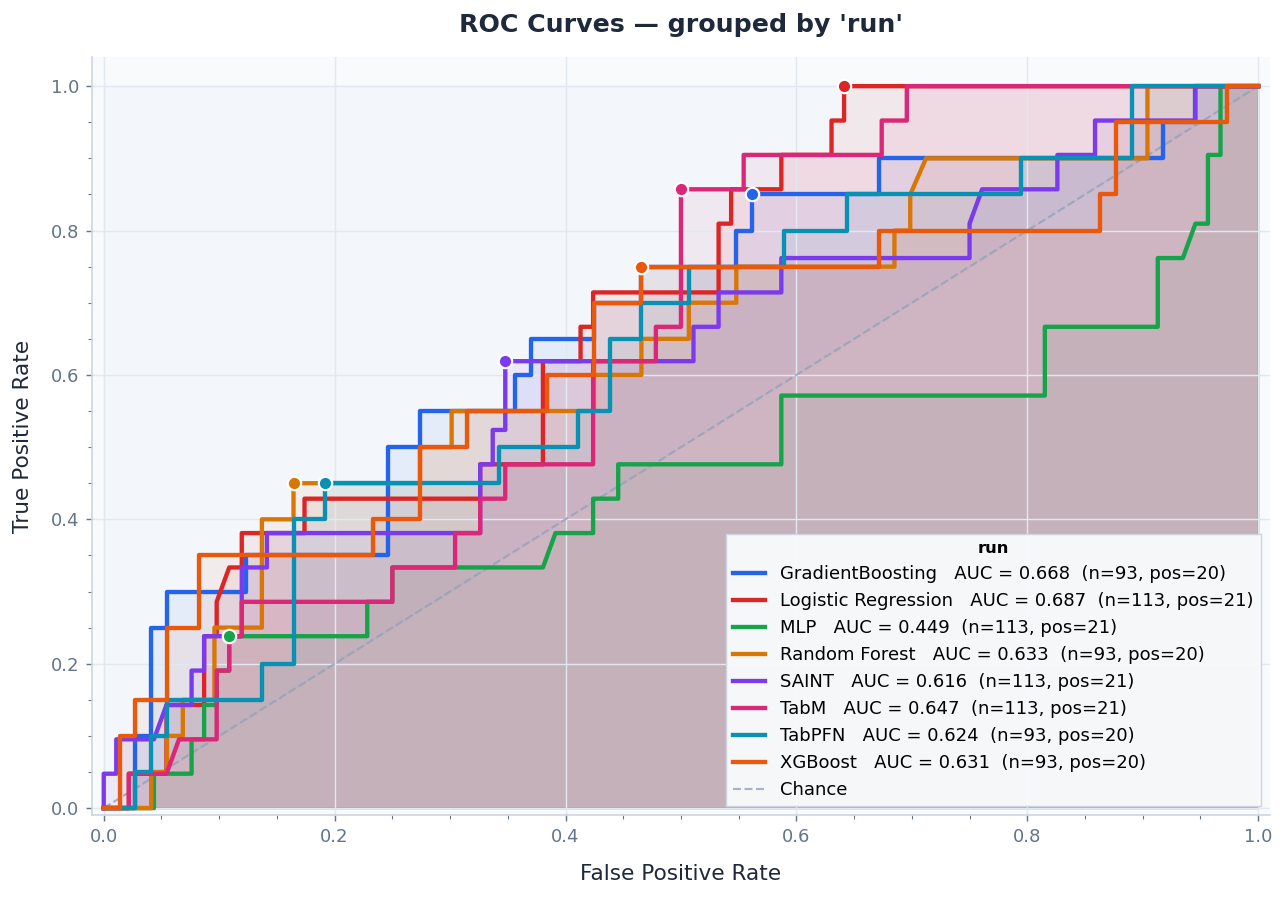

In [5]:
def _roc_key(run: str, split: str, stage: str, group_by: str) -> str:
    dispatch = {
        "run":       run,
        "stage":     stage,
        "split":     split,
        "run+stage": f"{run} ({stage})",
        "run+split": f"{run} ({split})",
    }
    return dispatch.get(group_by, run)


def plot_roc(
    preds: dict,
    group_by: str = "run",
    figsize: tuple = (10, 7),
    title: str | None = None,
) -> plt.Figure | None:
    if not preds:
        print("No prediction data loaded.")
        return None

    groups: dict[str, list[pd.DataFrame]] = {}
    for (run, split, stage), pred_df in sorted(preds.items()):
        key = _roc_key(run, split, stage, group_by)
        groups.setdefault(key, []).append(pred_df)

    fig, ax = plt.subplots(figsize=figsize)
    plotted = 0

    for i, (label, dfs) in enumerate(sorted(groups.items())):
        combined = pd.concat([d for d in dfs if not d.empty], ignore_index=True)
        if combined.empty or "reintervention_prob" not in combined.columns:
            print(f"  Skipping '{label}': no probability scores found.")
            continue
        yt = combined["reintervention_gt"].values
        yp = combined["reintervention_prob"].values
        if len(np.unique(yt)) < 2:
            print(f"  Skipping '{label}': only one class present (all GT = {yt[0]}).")
            continue

        fpr, tpr, _ = roc_curve(yt, yp)
        roc_auc     = sklearn_auc(fpr, tpr)
        n_pos       = int(yt.sum())
        color       = _PALETTE[i % len(_PALETTE)]

        # filled area under curve
        ax.fill_between(fpr, tpr, alpha=0.07, color=color, zorder=1)
        # main curve
        ax.plot(
            fpr, tpr,
            color=color, lw=2.4, zorder=3,
            label=f"{label}   AUC = {roc_auc:.3f}  (n={len(yt)}, pos={n_pos})",
        )
        # dot at nearest-to-top-left operating point
        best_idx = np.argmax(tpr - fpr)
        ax.scatter(
            fpr[best_idx], tpr[best_idx],
            s=55, color=color, zorder=5, edgecolors="white", linewidths=1.2,
        )
        plotted += 1

    if plotted == 0:
        print("Nothing to plot.")
        plt.close(fig)
        return None

    # chance line
    ax.plot([0, 1], [0, 1], linestyle="--", color="#94A3B8", lw=1.2,
            alpha=0.8, zorder=2, label="Chance")

    # shaded "better than chance" triangle
    ax.fill_between([0, 1], [0, 1], [1, 1], alpha=0.018, color="#2563EB")

    ax.set_xlim([-0.01, 1.01])
    ax.set_ylim([-0.01, 1.04])
    ax.xaxis.set_minor_locator(MultipleLocator(0.05))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))

    ax.set_xlabel("False Positive Rate", labelpad=10)
    ax.set_ylabel("True Positive Rate", labelpad=10)
    ax.set_title(title or f"ROC Curves — grouped by '{group_by}'")

    legend = ax.legend(
        loc="lower right",
        framealpha=0.97,
        edgecolor=_SPINE,
        fancybox=False,
        title=group_by.replace("+", " × "),
        title_fontproperties={"weight": "semibold", "size": 9},
        handlelength=1.8,
    )
    legend.get_frame().set_linewidth(0.8)

    plt.tight_layout()
    # plt.show()
    return fig


fig_roc = plot_roc(preds, group_by=ROC_GROUP_BY, figsize=FIG_SIZE)
fig_roc.savefig(f"{OUTPUT_DIR}/ROC_all.png", dpi=300, bbox_inches='tight')

## 5. Per-metric Bar Chart

**What:** Side-by-side bars for a selected set of metrics across all loaded result entries. Each bar group is one (model, split, stage) combination; each colour is one metric.

**How to read it:**
- The dashed line at 0.5 marks chance level
- Numbers above each bar are the exact values
- Edit `BAR_METRICS` in the config cell to choose which metrics to show

**Helps with:** Quickly spotting which model leads on a specific metric (e.g. recall matters most clinically here — missing a reintervention is worse than a false alarm).

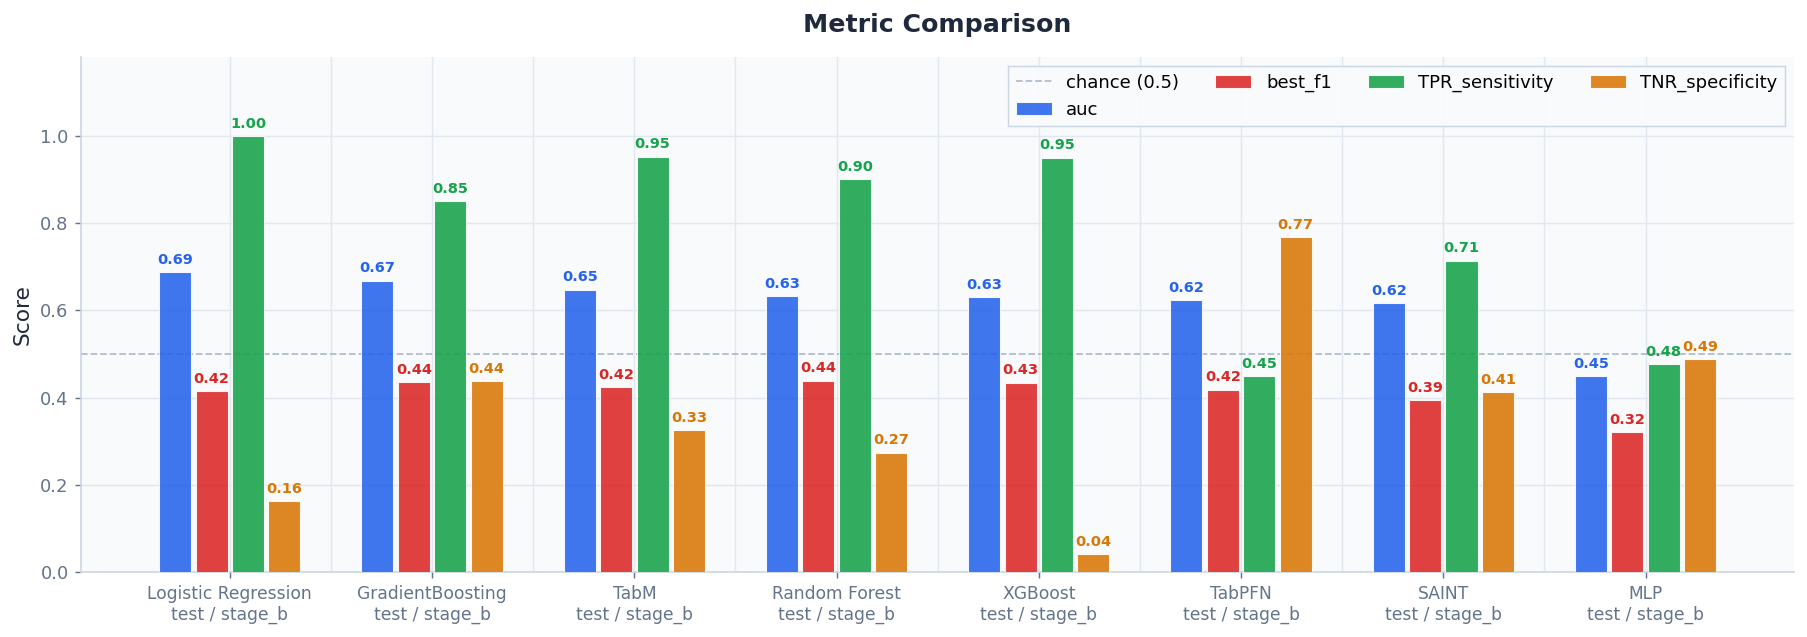

In [6]:
def plot_bars(
    df: pd.DataFrame,
    metrics: list[str] = BAR_METRICS,
    figsize: tuple = (14, 5),
) -> None:
    if df.empty:
        print("No data.")
        return

    avail = [m for m in metrics if m in df.columns]
    if not avail:
        print("None of the requested BAR_METRICS are in the loaded results.")
        return

    sorted_df = df.sort_values("auc", ascending=False).reset_index(drop=True)
    x_labels  = sorted_df.apply(
        lambda r: f"{r['run']}\n{r['split']} / {r['stage']}", axis=1
    )
    x      = np.arange(len(sorted_df))
    n_met  = len(avail)
    width  = 0.72 / n_met

    fig, ax = plt.subplots(figsize=figsize)

    for j, metric in enumerate(avail):
        offset = (j - n_met / 2 + 0.5) * width
        vals   = sorted_df[metric].values
        color  = _PALETTE[j % len(_PALETTE)]

        bars = ax.bar(
            x + offset, vals,
            width=width * 0.88,
            color=color,
            alpha=0.88,
            label=metric,
            zorder=3,
            edgecolor="white",
            linewidth=0.6,
        )
        # value labels on top
        for bar, v in zip(bars, vals):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.012,
                f"{v:.2f}",
                ha="center", va="bottom",
                fontsize=8, color=color, fontweight="600",
            )

    # chance baseline
    ax.axhline(0.5, color="#94A3B8", lw=1.0, ls="--", alpha=0.7, zorder=2,
               label="chance (0.5)")

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=9.5)
    ax.set_ylim(0, 1.18)
    ax.set_ylabel("Score")
    ax.set_title("Metric Comparison")

    legend = ax.legend(
        loc="upper right", fontsize=10,
        framealpha=0.96, edgecolor=_SPINE,
        fancybox=False, ncol=min(n_met, 5),
    )
    legend.get_frame().set_linewidth(0.8)

    # light vertical separators between groups
    for xi in x[:-1]:
        ax.axvline(xi + 0.5, color=_GRID, lw=0.8, zorder=1)

    plt.tight_layout()
    # plt.show()
    return fig


fig = plot_bars(df)
fig.savefig(f"{OUTPUT_DIR}/Metric_comparison_bar_chart.png", dpi=300, bbox_inches='tight')


## 6. Custom Cross-reference ROC

**What:** Three ready-made examples that call `plot_roc()` directly with a specific `group_by` override, independent of the `ROC_GROUP_BY` set in the config cell.

- **Example A** — stage_a vs stage_b: did fine-tuning the backbone actually help?
- **Example B** — method × stage grid: e.g. `TabM (stage_a)` vs `TabM (stage_b)` vs `MLP (stage_b)`
- **Example C** — train / val / test for one model at one stage: the clearest overfitting check

**Helps with:** Ad-hoc comparisons without having to re-run the whole notebook or change the config cell.

In [7]:
# Example A: compare stage_a vs stage_b
# (requires FILTER_STAGE=None and FILTER_SPLIT="test" in the config cell)
# plot_roc(preds, group_by="stage", title="Stage A vs Stage B — test split")

In [8]:
# Example B: one curve per (method × stage)
# fig = plot_roc(preds, group_by="run+stage", title="Method × Stage — test split")

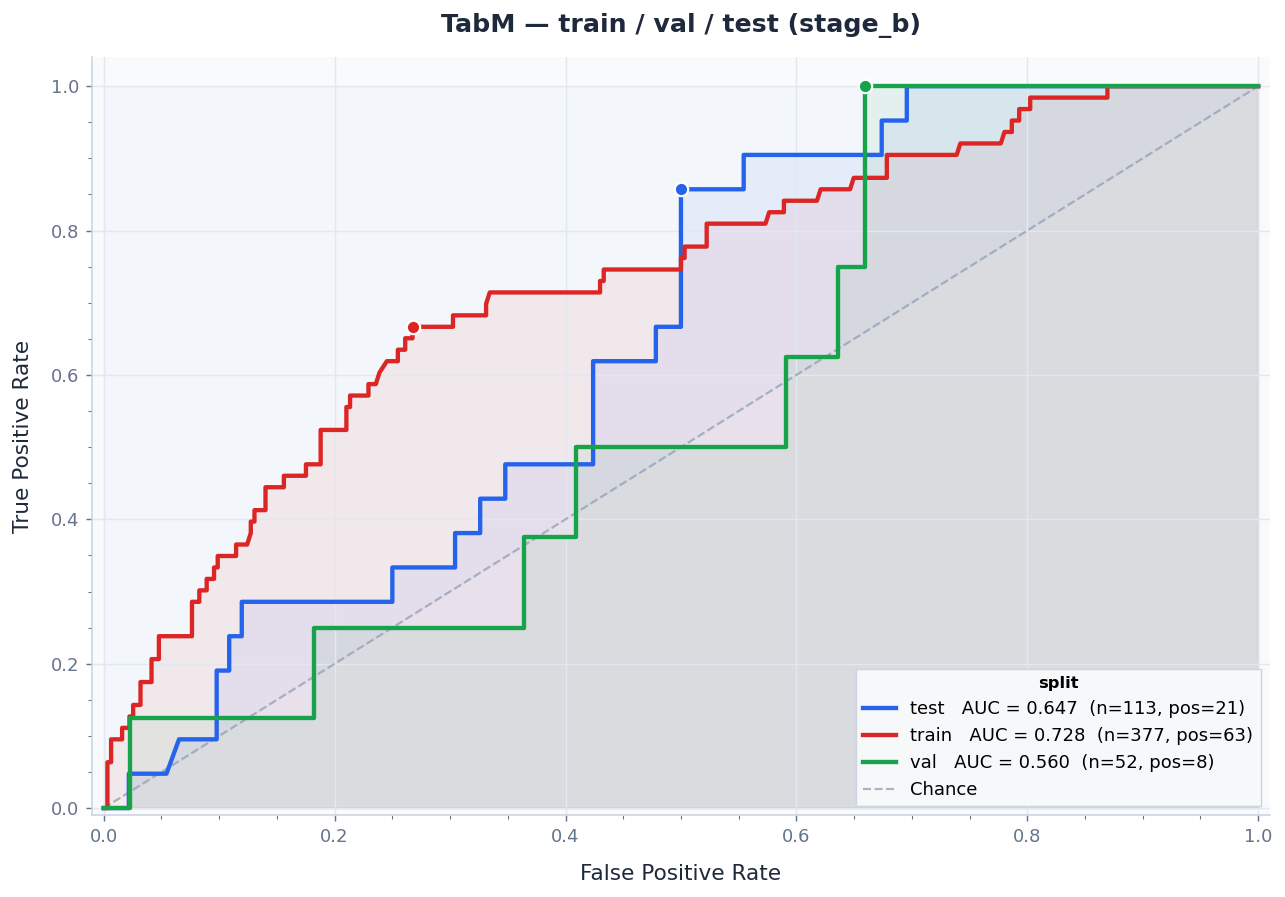

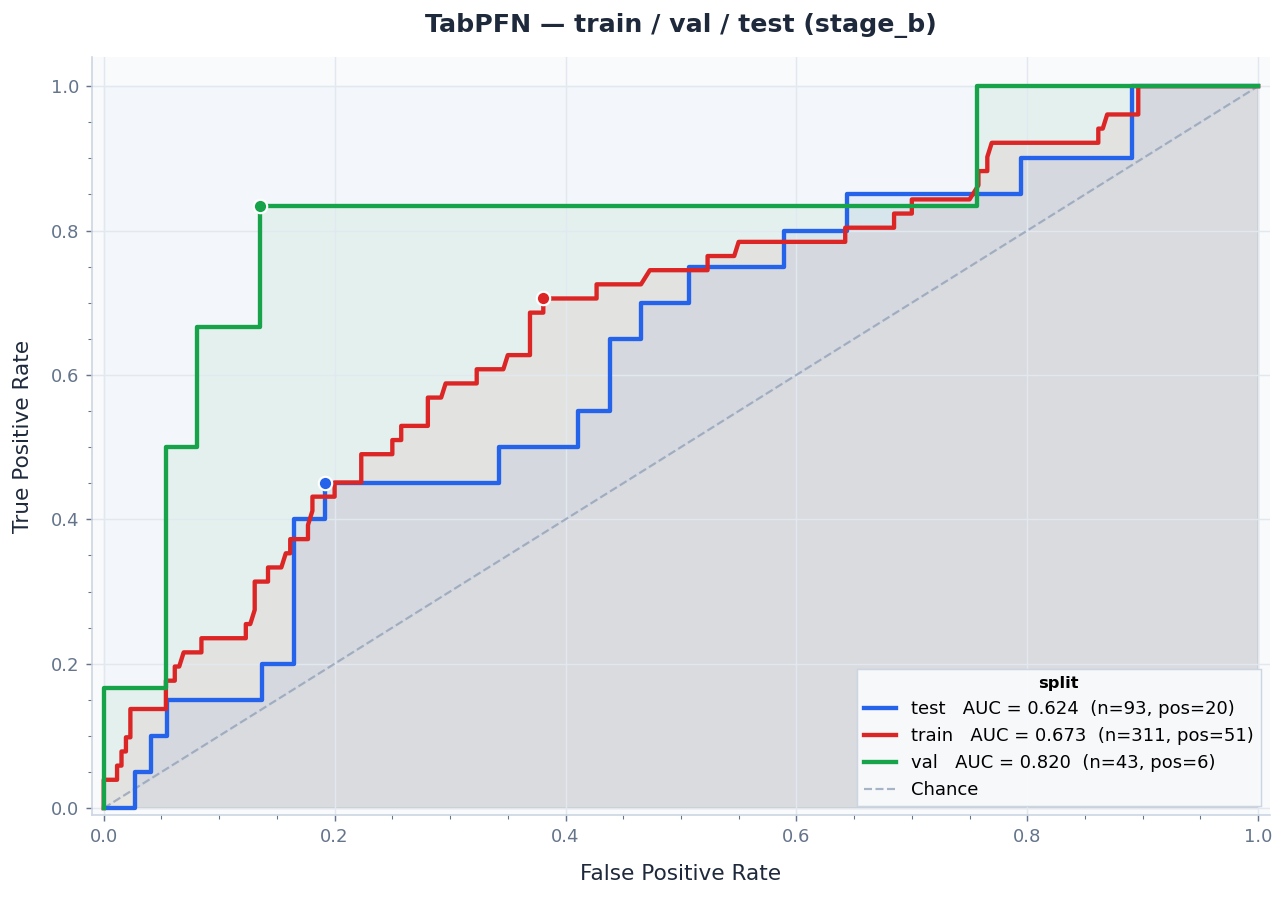

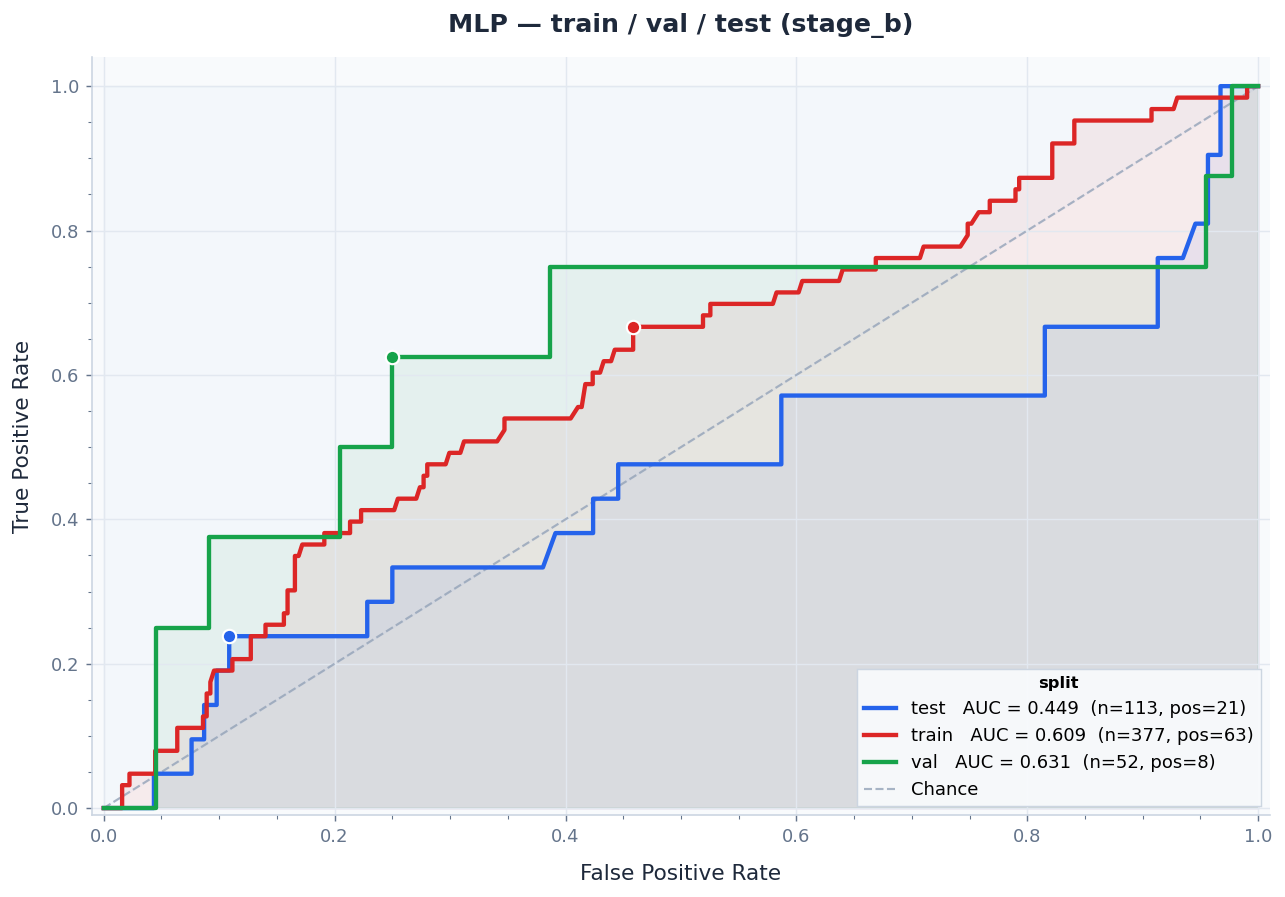

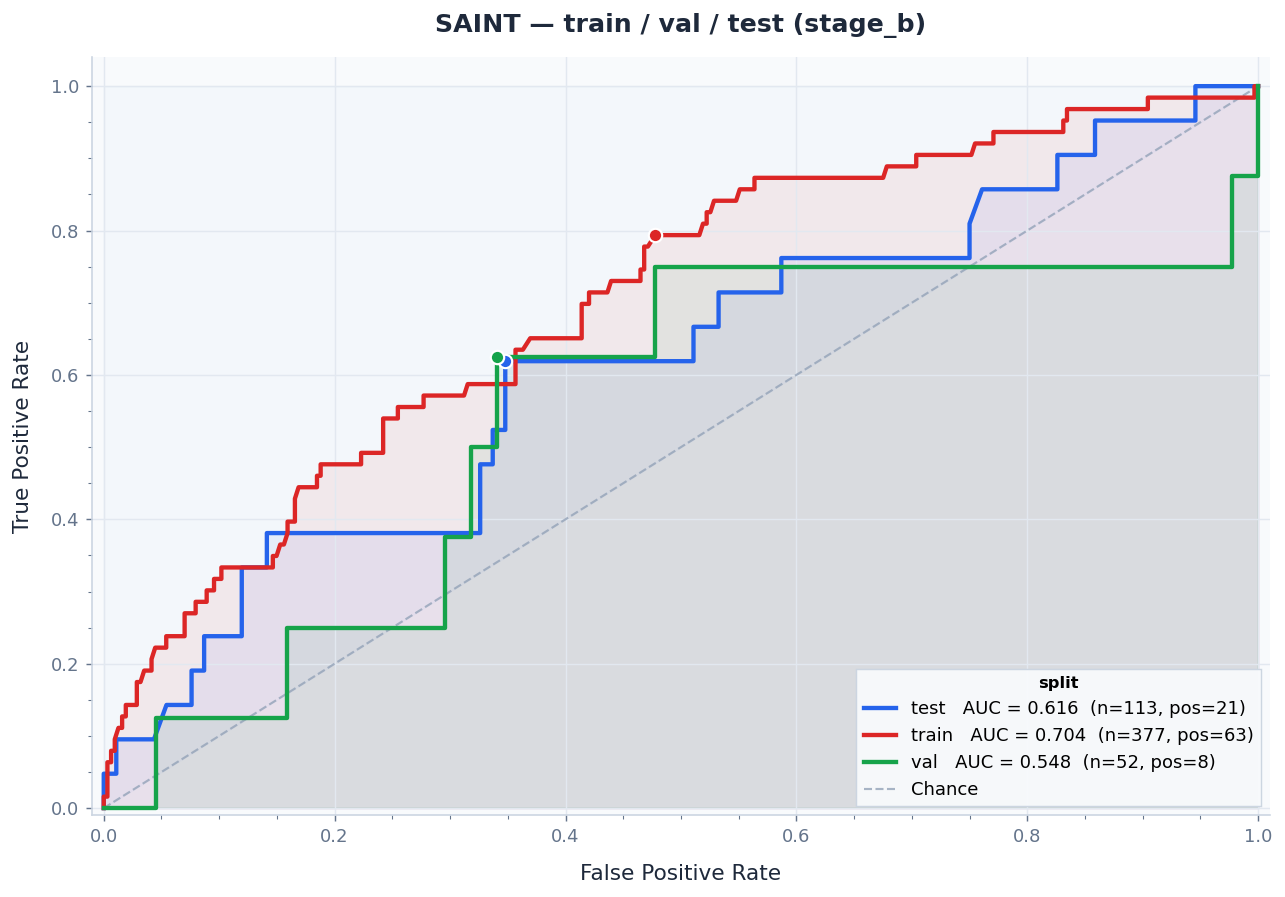

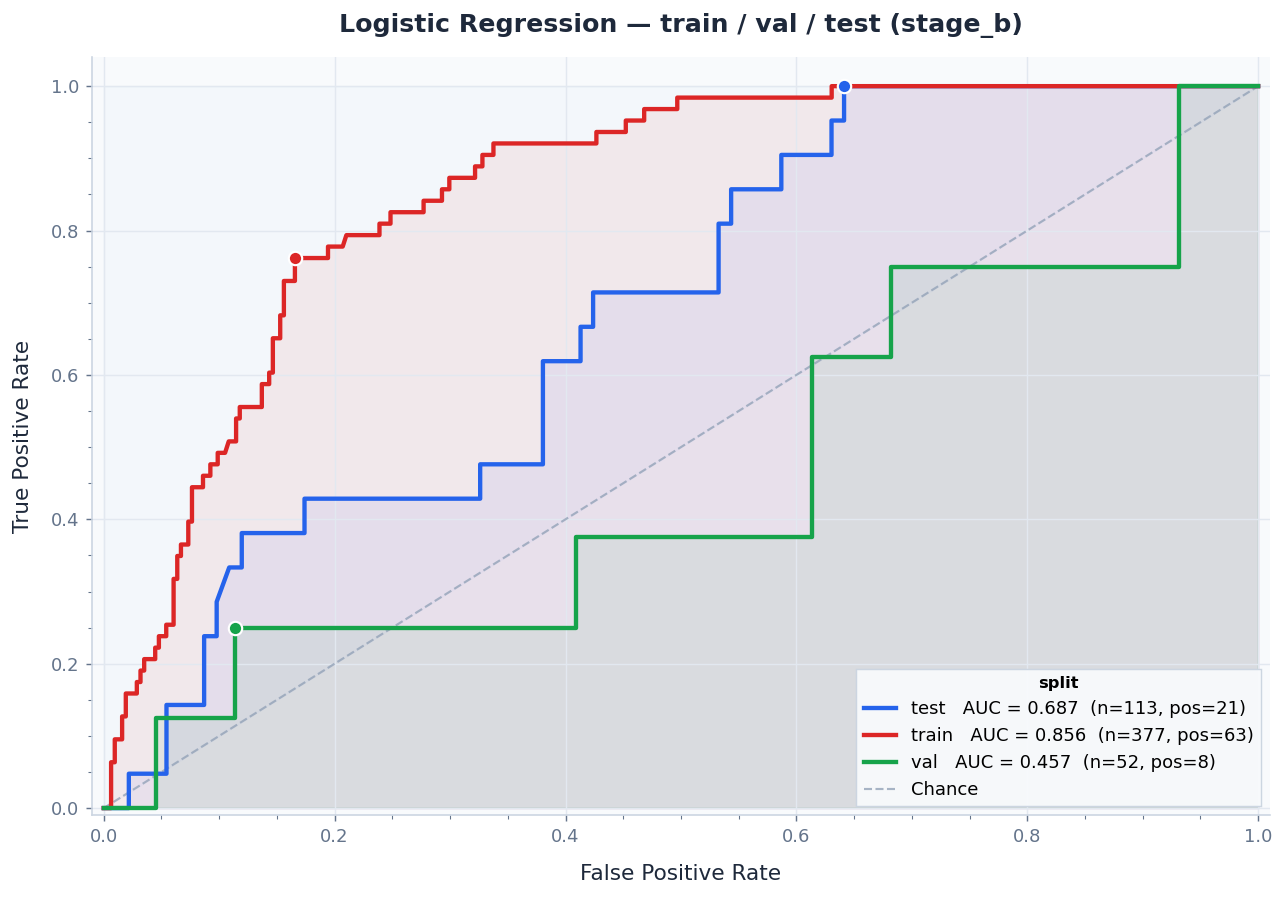

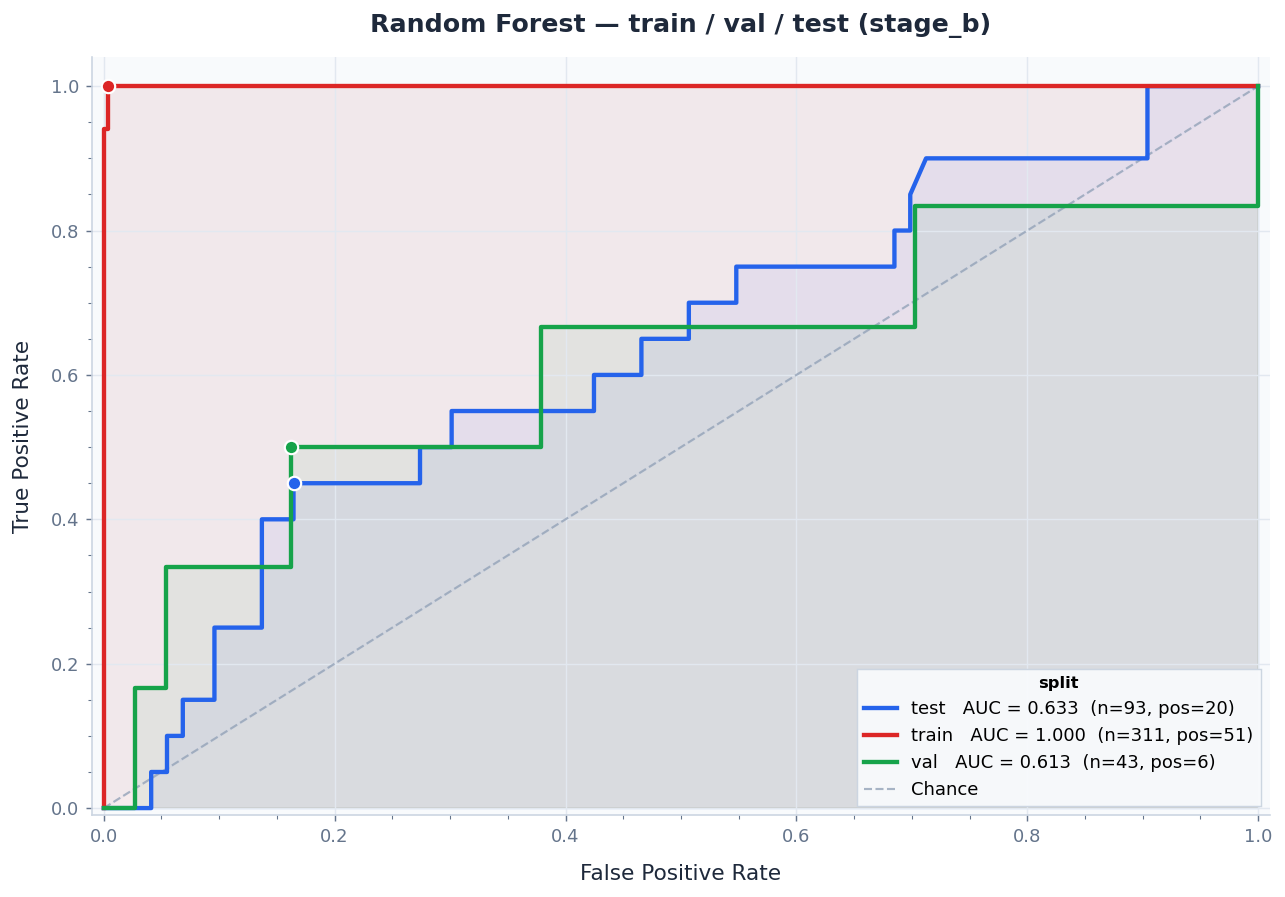

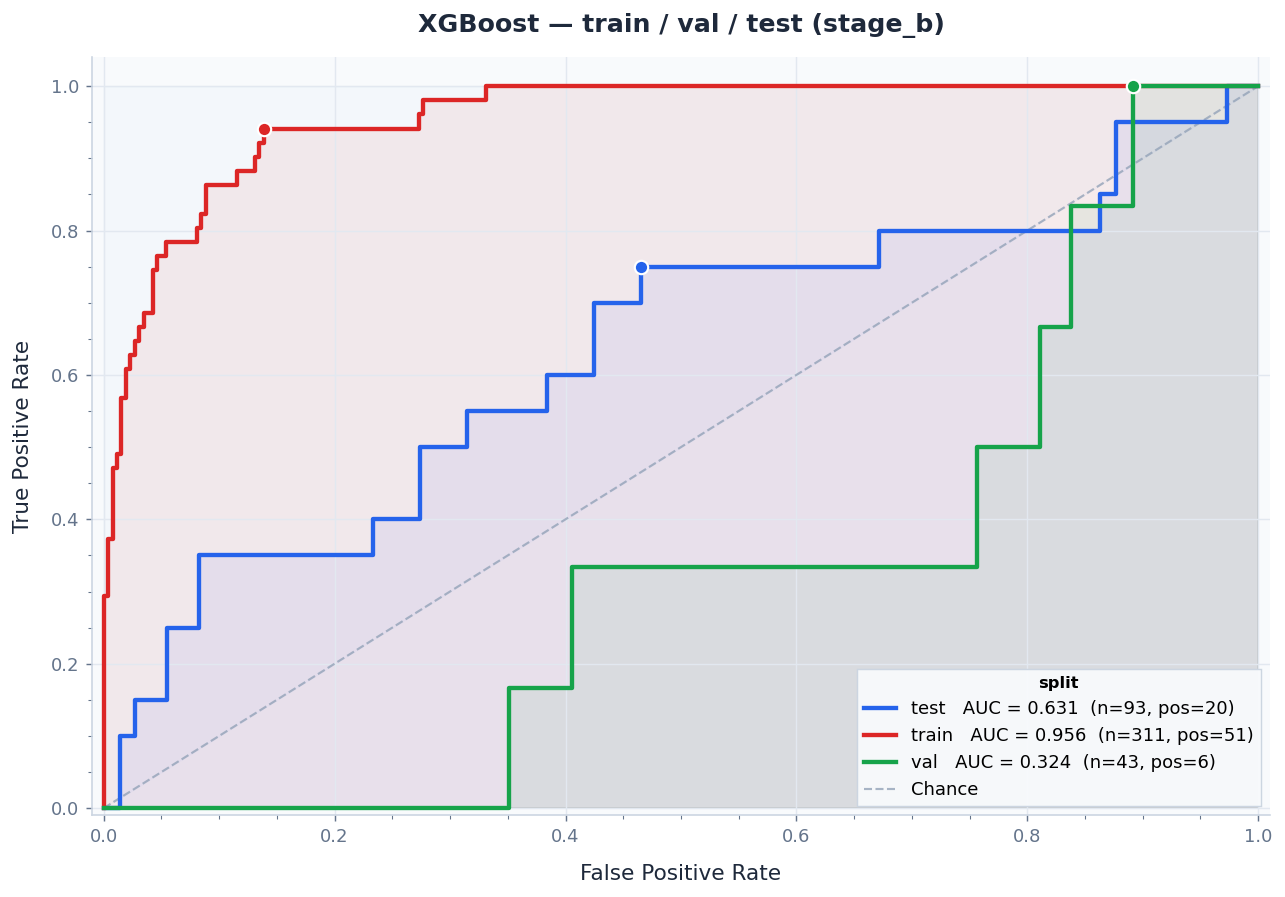

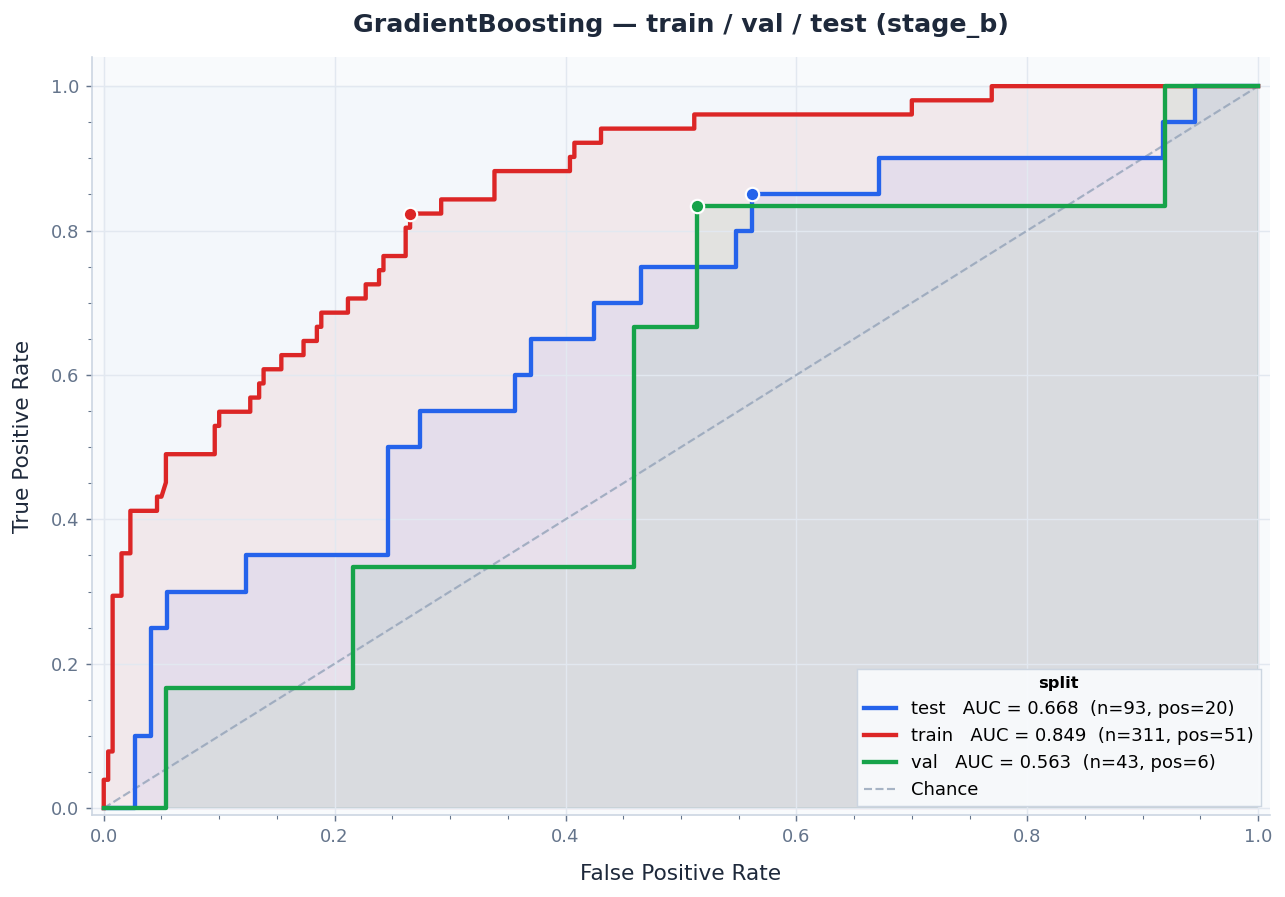

In [9]:
# Example C: train / val / test for one stage of the first run
for i, run in enumerate(RESULT_DIRS.keys()):
    _run_name = list(RESULT_DIRS.keys())[i]
    _, preds_all_splits = load_all(
        {_run_name: RESULT_DIRS[_run_name]},
        filter_stage="stage_b",
        filter_split=None,
    )
    fig = plot_roc(preds_all_splits, group_by="split",
            title=f"{_run_name} — train / val / test (stage_b)")
    fig.savefig(f"{OUTPUT_DIR}/{_run_name}_roc_split_comparison_stageB.png", dpi=300, bbox_inches='tight')


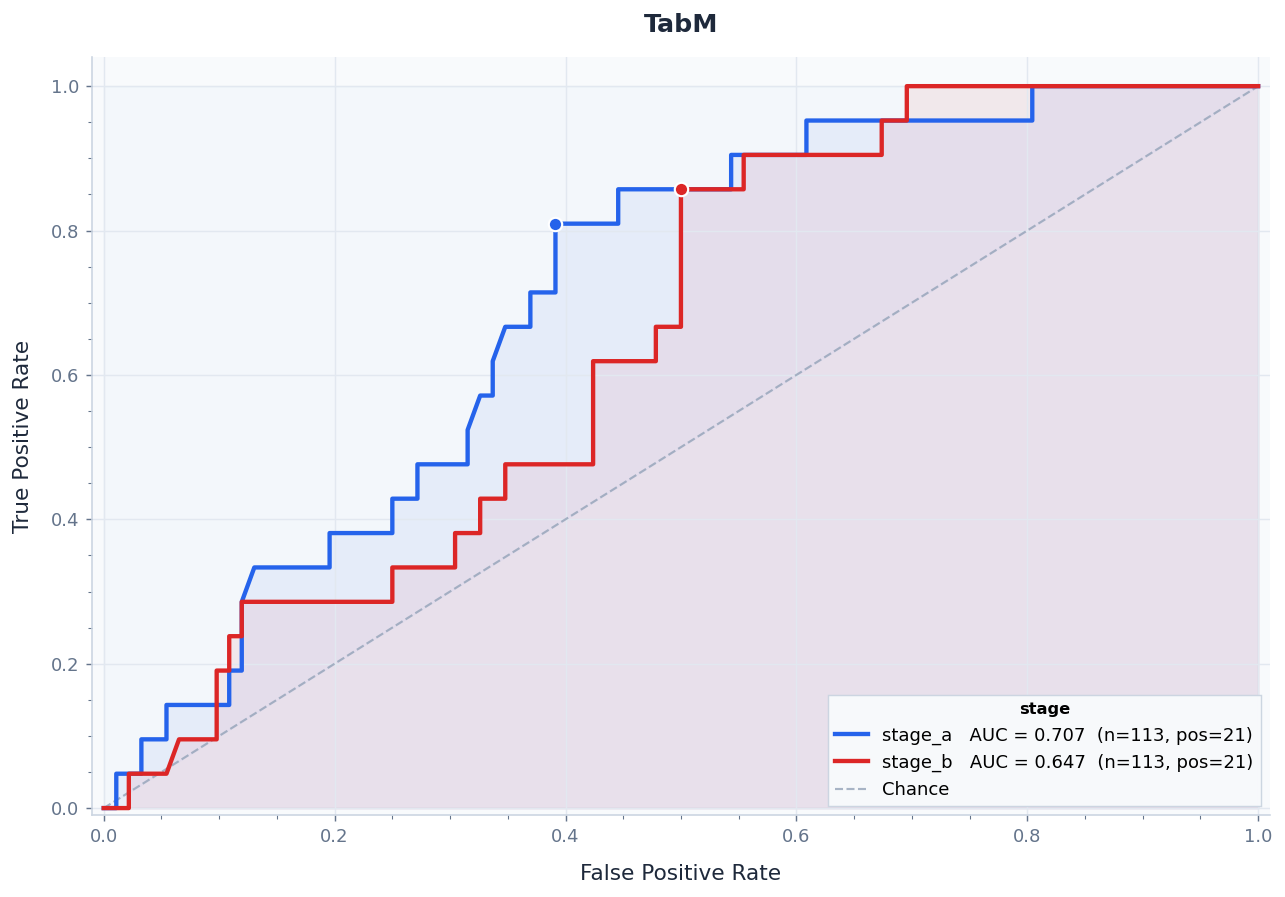

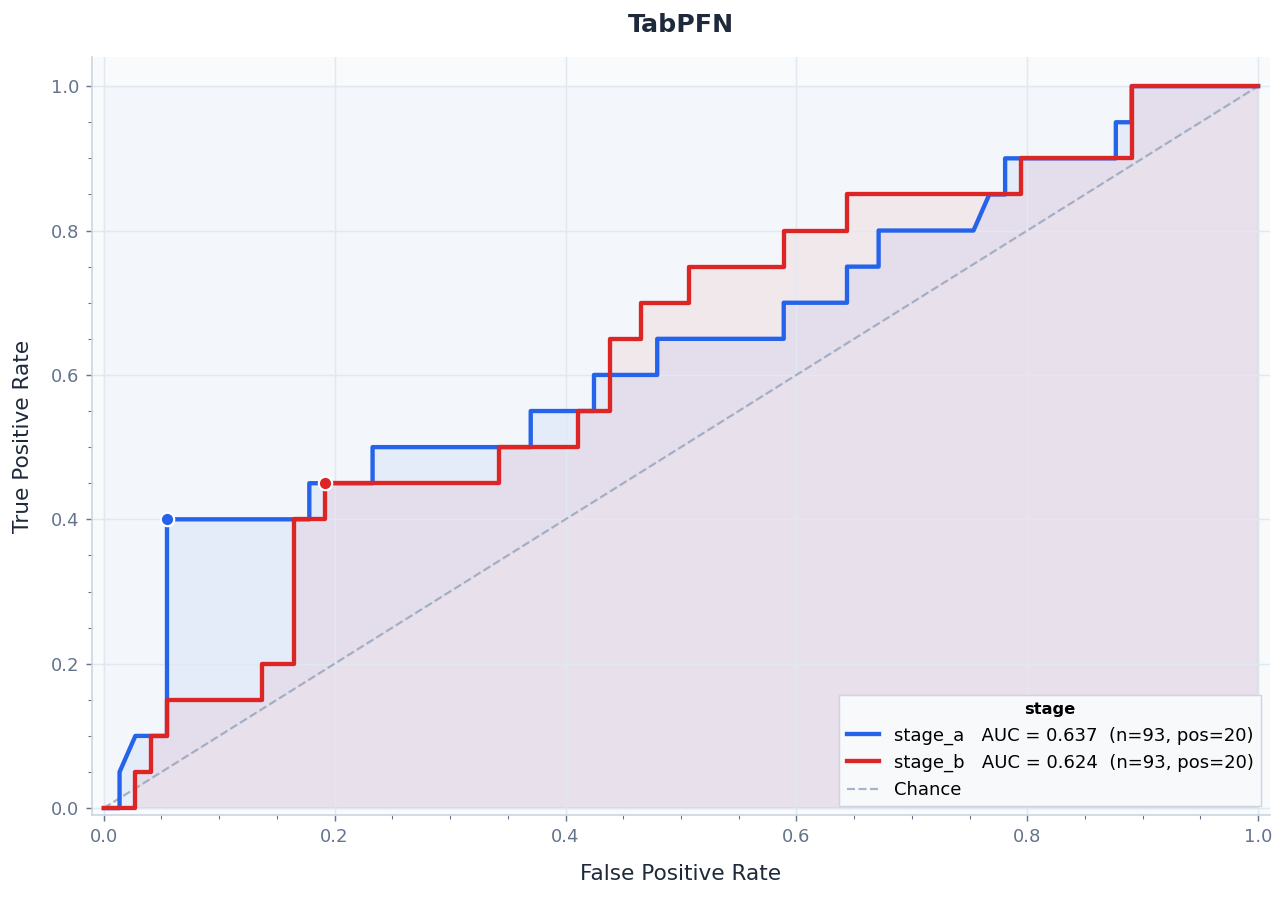

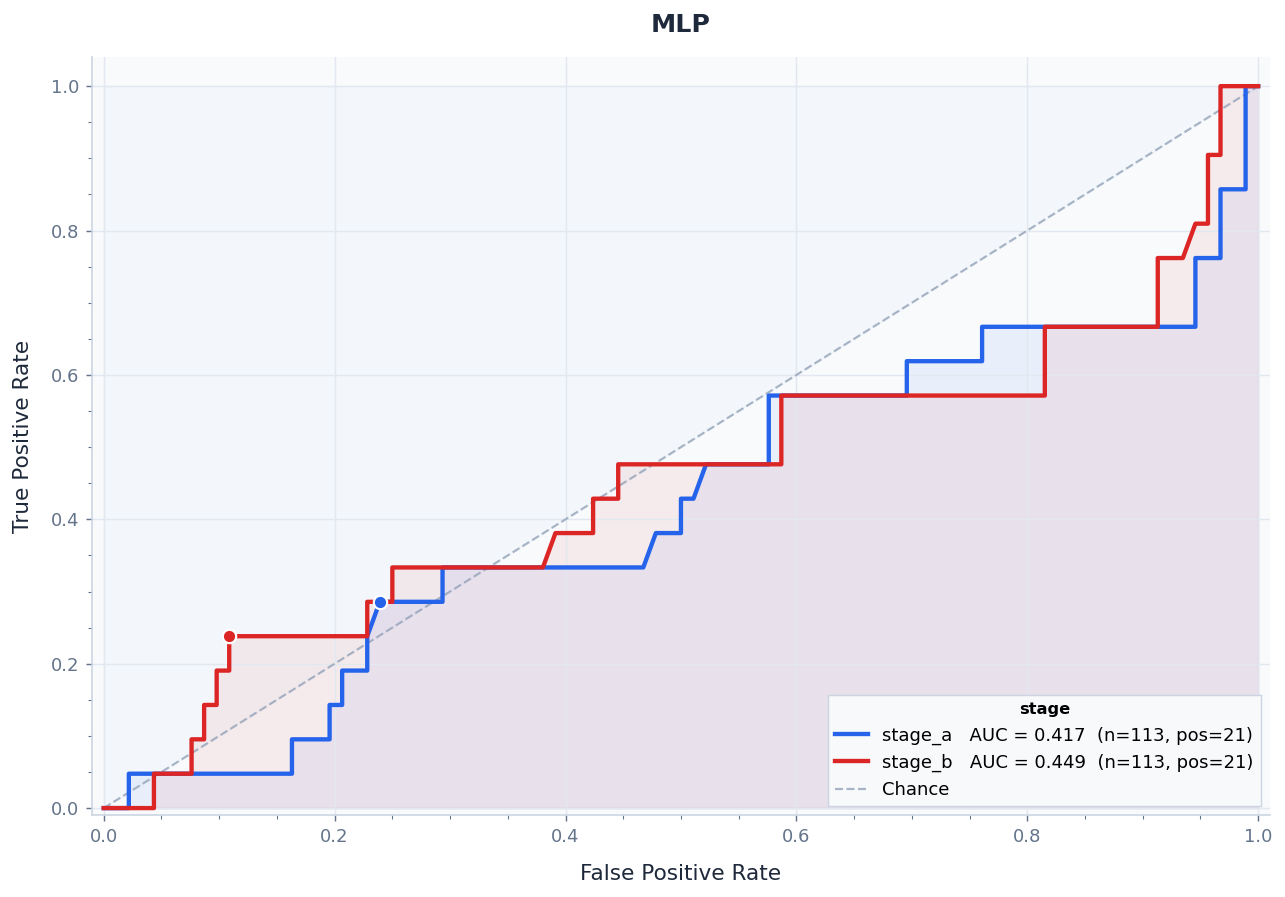

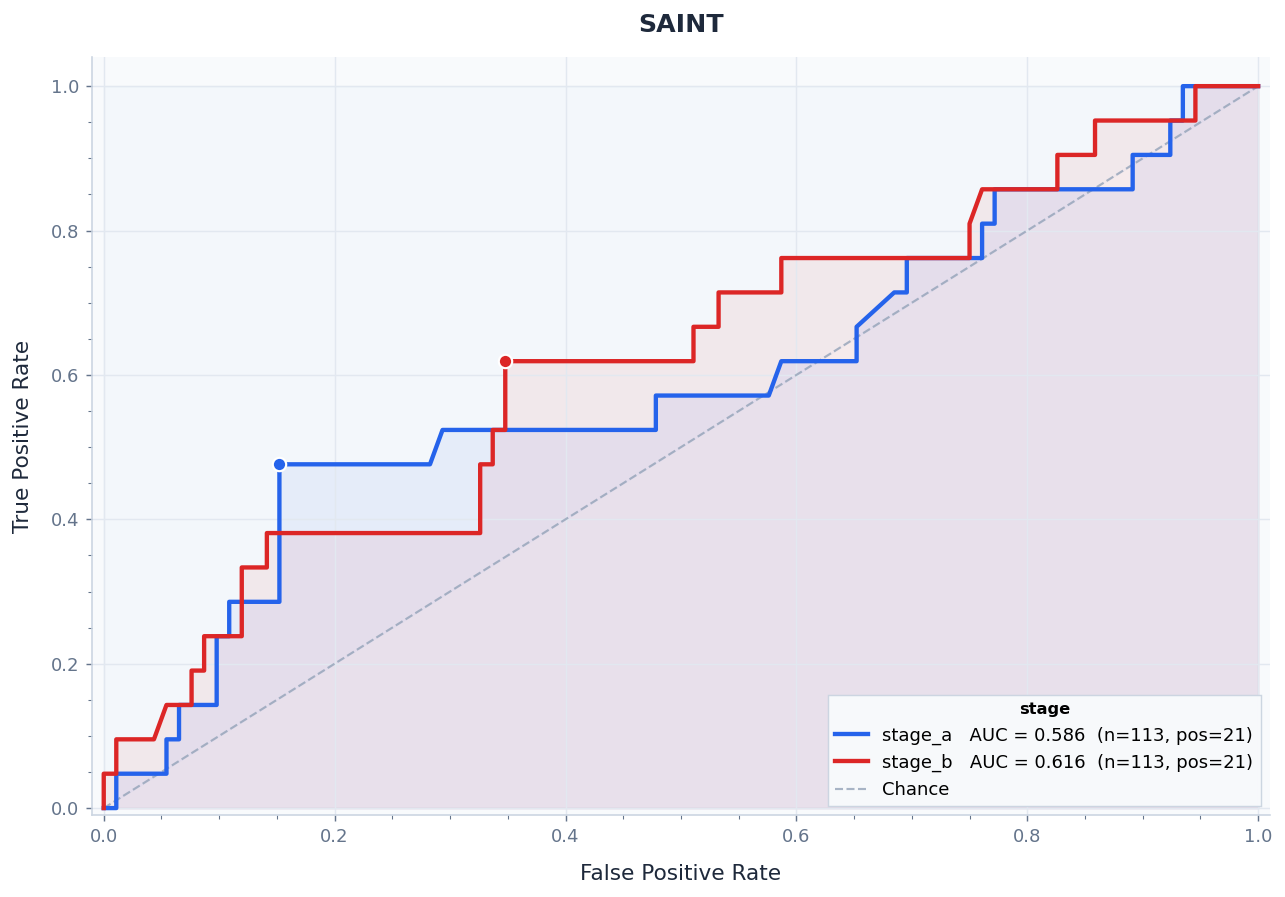

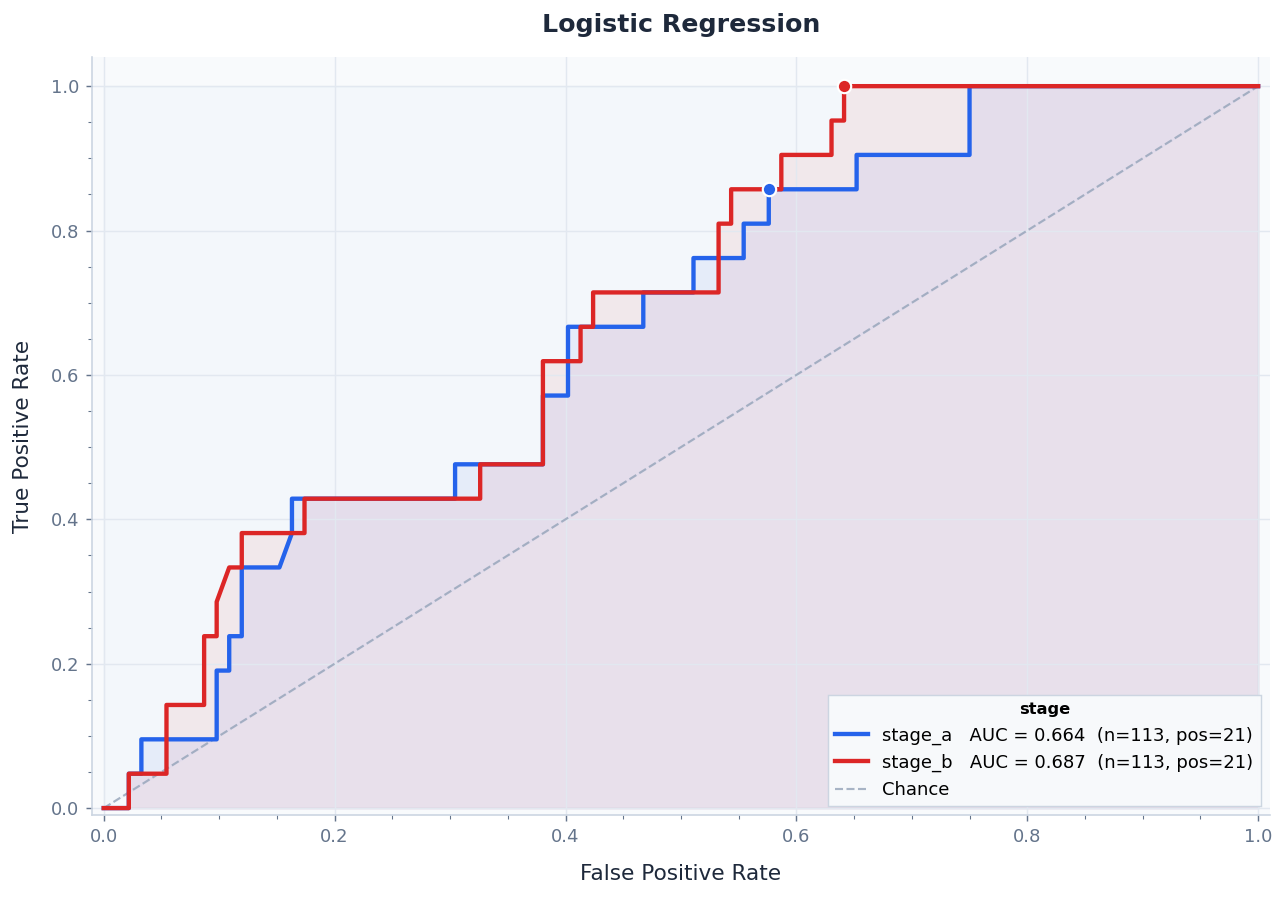

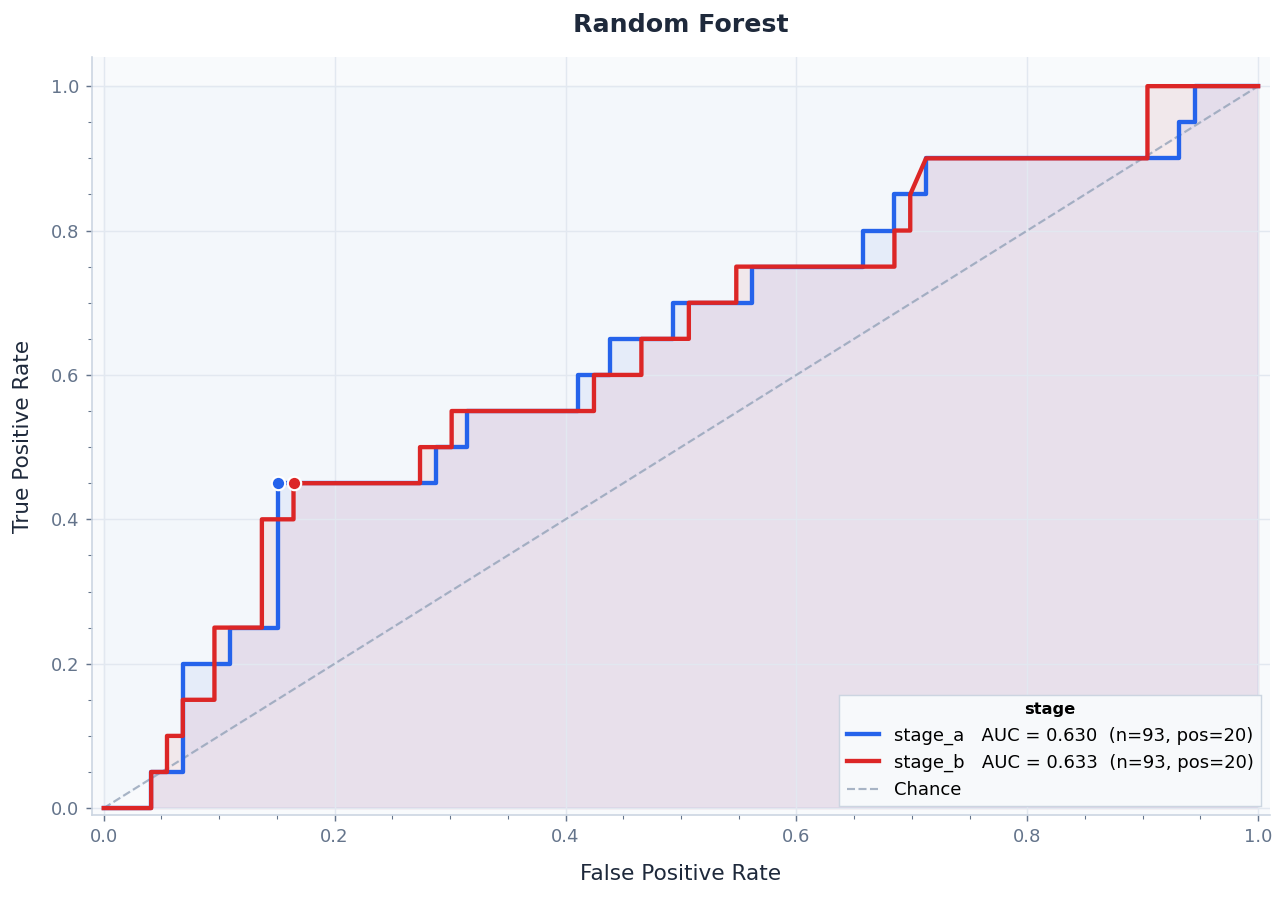

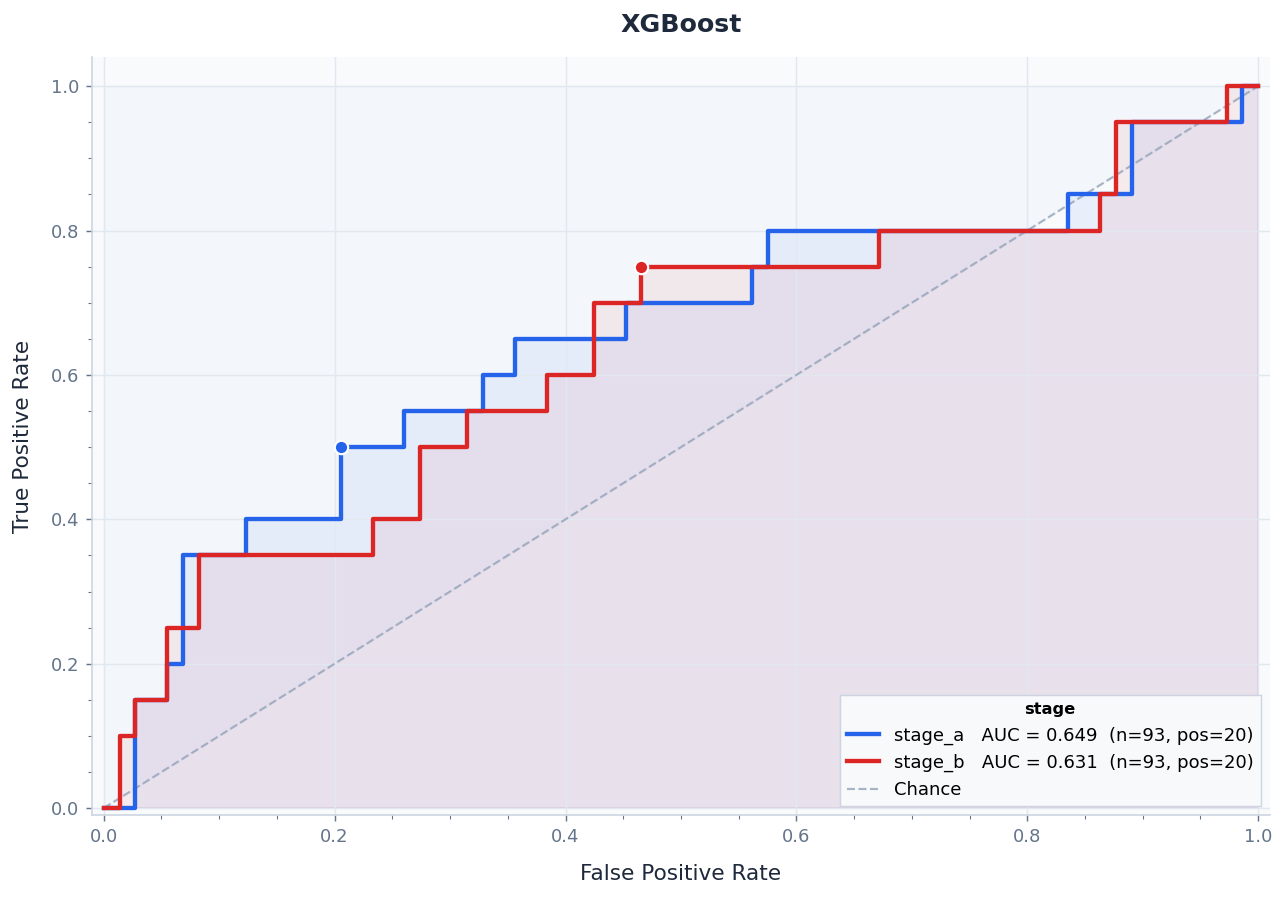

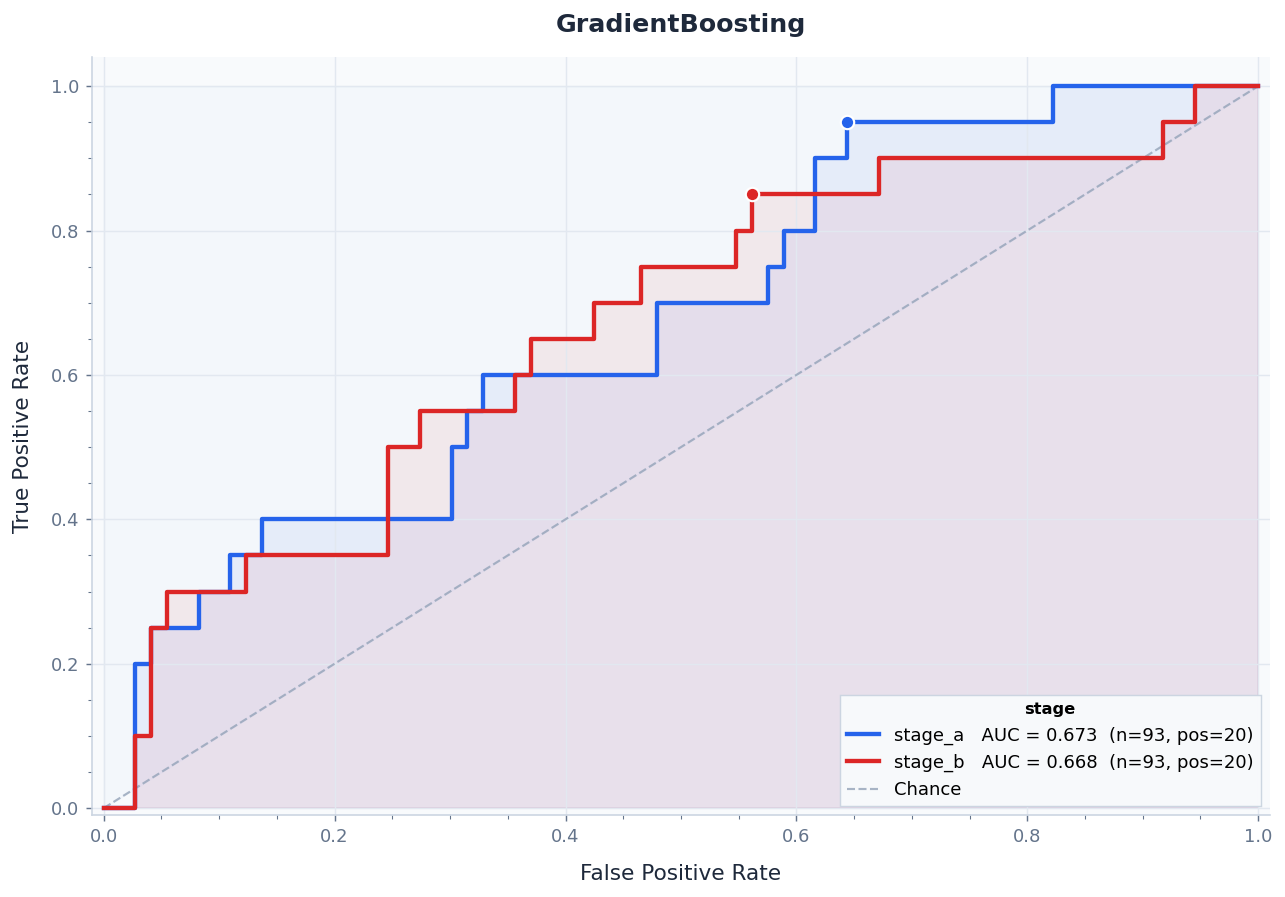

In [10]:
# Loop through all and compare test stage A vs B
for i, run in enumerate(RESULT_DIRS.keys()):
    _run_name = list(RESULT_DIRS.keys())[i]
    _, preds_all_splits = load_all(
        {_run_name: RESULT_DIRS[_run_name]},
        filter_stage=None,
        filter_split="test",
    )
    fig = plot_roc(preds_all_splits, group_by="stage",
            title=f"{_run_name}")
    fig.savefig(f"{OUTPUT_DIR}/{_run_name}_roc_stageA_vs_stageB_test.png", dpi=300, bbox_inches='tight')

## 7. AUROC Forest Plot with Bootstrap Confidence Intervals

**What:** Shows each model/split AUC as a dot with a 95% Conf. Int. whisker around it.

**How it works:** The model predictions (probability + true label per patient) are already saved. The bootstrap resamples those patient records 1 000 times with replacement — each resample is a slightly different fake test set of the same size. AUC is recomputed on each resample, giving 1 000 AUC values. The 2.5th and 97.5th percentiles of those values form the Conf. Int. The model itself is never re-run.

**How to read it:**
- Wide whiskers = unreliable AUC (too few patients or too few positive cases)
- If two models' whiskers overlap heavily, the difference between them is not meaningful
- If train and test whiskers do not overlap, that is strong evidence of overfitting

**Why it matters:** With ~100 test patients an AUC of 0.72 could easily have been 0.61 or 0.83 on a slightly different sample. The Conf. Int. makes that uncertainty explicit instead of hiding it behind a single number.

Color: **blue** = train · **amber** = val · **green** = test

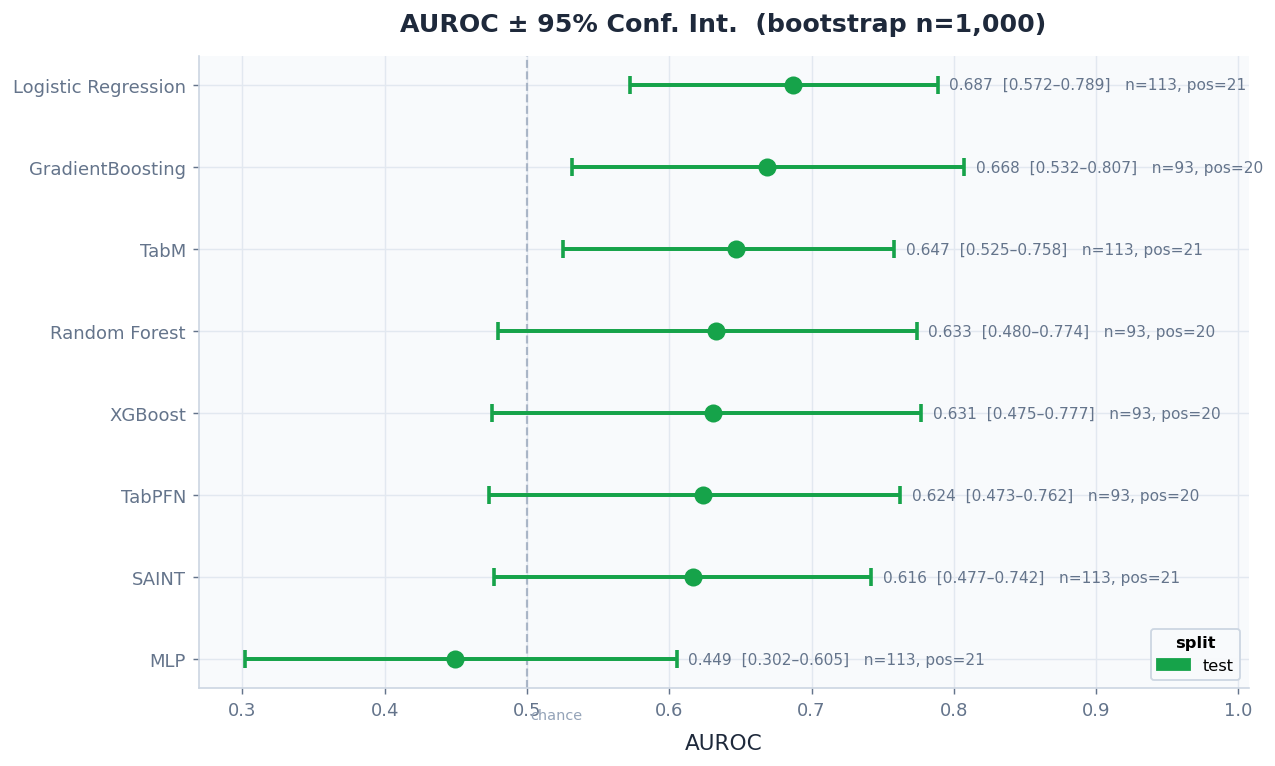

In [11]:
N_BOOT = 1_000   # ← increase to 5000 for publication-quality Conf. Int.

_SPLIT_COLORS = {"train": "#2563EB", "val": "#D97706", "test": "#16A34A"}


def _bootstrap_auc_ci(y_true, y_prob, n_boot=N_BOOT, ci=0.95, seed=42):
    """Percentile-bootstrap 95% Conf. Int. for AUROC."""
    rng  = np.random.default_rng(seed)
    n    = len(y_true)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt, yp = y_true[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        fpr, tpr, _ = roc_curve(yt, yp)
        aucs.append(sklearn_auc(fpr, tpr))
    if len(aucs) < 20:
        return float("nan"), float("nan")
    a = (1 - ci) / 2
    return float(np.percentile(aucs, a * 100)), float(np.percentile(aucs, (1 - a) * 100))


def plot_auc_forest(preds, group_by=ROC_GROUP_BY, n_boot=N_BOOT):
    if not preds:
        print("No prediction data.")
        return

    rows = []
    for (run, split, stage), pred_df in sorted(preds.items()):
        if pred_df.empty or "reintervention_prob" not in pred_df.columns:
            continue
        yt = pred_df["reintervention_gt"].values
        yp = pred_df["reintervention_prob"].values
        if len(np.unique(yt)) < 2:
            continue
        fpr, tpr, _ = roc_curve(yt, yp)
        auc_val      = sklearn_auc(fpr, tpr)
        lo, hi       = _bootstrap_auc_ci(yt, yp, n_boot=n_boot)
        label        = _roc_key(run, split, stage, group_by)
        rows.append({"label": label, "auc": auc_val, "lo": lo, "hi": hi,
                     "n": len(yt), "n_pos": int(yt.sum()), "split": split})

    if not rows:
        print("Nothing to plot — check that preds contains probability scores.")
        return

    rows.sort(key=lambda r: r["auc"])
    y_pos  = np.arange(len(rows))
    colors = [_SPLIT_COLORS.get(r["split"], "#7C3AED") for r in rows]

    h = max(3.5, len(rows) * 0.75)
    fig, ax = plt.subplots(figsize=(10, h))

    for i, (row, col) in enumerate(zip(rows, colors)):
        err_lo = row["auc"] - row["lo"] if not np.isnan(row["lo"]) else 0
        err_hi = row["hi"] - row["auc"] if not np.isnan(row["hi"]) else 0
        ax.errorbar(row["auc"], i, xerr=[[err_lo], [err_hi]],
                    fmt="o", color=col, ms=9, lw=2.2,
                    capsize=5, capthick=2, zorder=4)
        hi_x = row["hi"] if not np.isnan(row["hi"]) else row["auc"]
        ax.text(hi_x + 0.008, i,
                f"{row['auc']:.3f}  [{row['lo']:.3f}–{row['hi']:.3f}]"
                f"   n={row['n']}, pos={row['n_pos']}",
                va="center", ha="left", fontsize=8.5, color=_SUBTEXT)

    ax.axvline(0.5, color="#94A3B8", lw=1.2, ls="--", alpha=0.75, zorder=2)
    ax.text(0.502, -0.6, "chance", fontsize=8, color="#94A3B8", va="top")

    ax.set_yticks(y_pos)
    ax.set_yticklabels([r["label"] for r in rows], fontsize=10)
    ax.set_xlabel("AUROC", labelpad=8)
    ax.set_xlim(max(0.25, min(r["auc"] for r in rows) - 0.18),
                min(1.01, max(r["auc"] for r in rows) + 0.32))
    ax.set_title(f"AUROC ± 95% Conf. Int.  (bootstrap n={n_boot:,})", pad=14)

    patches = [mpatches.Patch(color=c, label=s)
               for s, c in _SPLIT_COLORS.items()
               if any(r["split"] == s for r in rows)]
    ax.legend(handles=patches, loc="lower right", fontsize=9,
              title="split", title_fontproperties={"size": 9, "weight": "semibold"})

    plt.tight_layout()
    # plt.show()
    return fig


fig = plot_auc_forest(preds, group_by=ROC_GROUP_BY)
fig.savefig(f"{OUTPUT_DIR}/AUROC_bootstrap.png", dpi=300, bbox_inches='tight')

## 8. Cross-model AUROC Matrix

**What:** A heatmap table — rows are models, columns are splits (train / val / test), each cell is the AUC for that combination. The Δ column on the right shows `train AUC − test AUC`.

**How to read it:**
- Read across a row to see how one model's AUC changes from training data to unseen test data
- Read down a column to compare models on the same split
- The Δ column flags overfitting: 🟢 < 0.02 no issue · 🟡 0.02–0.05 mild · 🔴 > 0.05 the model is memorising training data

**Why it matters:** The ROC curves and bar charts only show one split at a time. This matrix gives the complete picture in a single view — a large red Δ immediately tells you a model should not be trusted on new patients even if its test AUC looks acceptable.

Note: this section always loads all splits regardless of `FILTER_SPLIT` so every cell can be filled.

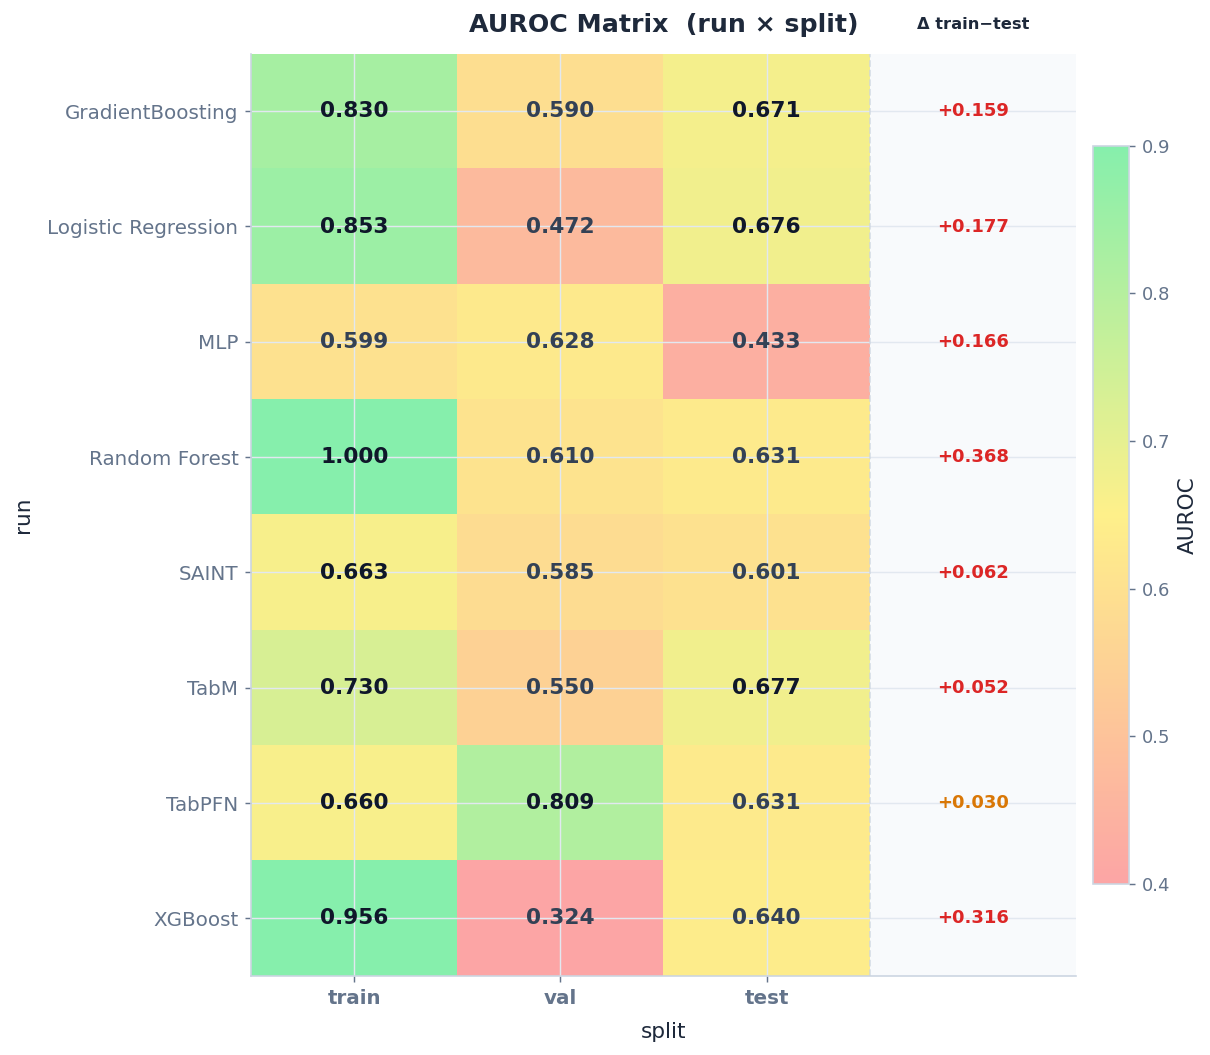

In [12]:
def plot_auc_matrix(df, row_key="run", col_key="split"):
    """Heatmap: rows = run, columns = split, cells = AUROC.
    Δ train−test drawn as an extra text column inside the same axes.
    """
    if df.empty or "auc" not in df.columns:
        print("No data.")
        return

    pivot = df.pivot_table(index=row_key, columns=col_key, values="auc", aggfunc="mean")
    if pivot.empty:
        print(f"Cannot pivot on {row_key} × {col_key} — check FILTER_STAGE/FILTER_SPLIT.")
        return

    col_order = [c for c in ["train", "val", "test"] if c in pivot.columns]
    col_order += [c for c in pivot.columns if c not in col_order]
    pivot = pivot[col_order]

    n_rows, n_cols = len(pivot), len(pivot.columns)
    has_delta = "train" in pivot.columns and "test" in pivot.columns

    # One extra virtual column for the Δ annotation
    n_display = n_cols + (1 if has_delta else 0)

    fig, ax = plt.subplots(
        figsize=(n_display * 2.0 + 1.2, max(2.4, n_rows * 0.85 + 1.2)),
        constrained_layout=True,
    )

    mat = pivot.values.astype(float)
    # imshow: cell (row i, col j) sits at data coords (x=j, y=i)
    im = ax.imshow(mat, cmap=_CMAP_AUC, vmin=0.40, vmax=0.90,
                   aspect="auto", zorder=1)

    # Extend x-axis to make room for the Δ column
    ax.set_xlim(-0.5, n_display - 0.5)

    # x-ticks only for the real data columns
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(pivot.columns, fontsize=11, fontweight="600")
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(pivot.index, fontsize=11)
    ax.set_xlabel(col_key, labelpad=8)
    ax.set_ylabel(row_key, labelpad=8)
    ax.set_title(f"AUROC Matrix  ({row_key} × {col_key})", pad=12)

    # Cell annotations (AUC values)
    for i in range(n_rows):
        for j in range(n_cols):
            v = mat[i, j]
            txt = "–" if np.isnan(v) else f"{v:.3f}"
            col = "#94A3B8" if np.isnan(v) else ("#0F172A" if v > 0.65 else "#334155")
            ax.text(j, i, txt, ha="center", va="center",
                    fontsize=12, fontweight="700", color=col, zorder=3)

    # Δ column — vertical separator + header + per-row values
    if has_delta:
        gap = pivot["train"].values - pivot["test"].values
        x_delta = n_cols   # one step right of the last real column

        # dashed separator
        ax.axvline(n_cols - 0.5, color=_SPINE, lw=1.0, ls="--", zorder=2, alpha=0.7)

        # column header (sits above row 0, i.e. at y = -0.75)
        ax.text(x_delta, -0.75, "Δ train−test",
                ha="center", va="center", fontsize=9,
                fontweight="600", color=_TEXT)

        for i, gv in enumerate(gap):
            if np.isnan(gv):
                lbl, col = "n/a", "#94A3B8"
            else:
                lbl = f"{gv:+.3f}"
                col = ("#DC2626" if gv > 0.05
                       else "#D97706" if gv > 0.02
                       else "#16A34A")
            ax.text(x_delta, i, lbl,
                    ha="center", va="center",
                    fontsize=10, fontweight="700", color=col, zorder=3)

    plt.colorbar(im, ax=ax, label="AUROC", shrink=0.8, pad=0.02)
    # plt.show()
    return fig


# Always load without split filter so all matrix cells are filled
_df_all, _ = load_all(RESULT_DIRS)
fig = plot_auc_matrix(_df_all, row_key="run", col_key="split")
fig.savefig(f"{OUTPUT_DIR}/AUROC_Matrix.png", dpi=300, bbox_inches='tight')

## 9. Pairwise Model Comparison (bootstrap significance)

**What:** For every pair of models in `RESULT_DIRS`, tests whether their AUC difference is statistically real or could just be random noise from the small dataset.

**How it works:**
1. Match both models' predictions to the same patients (by `pid`)
2. Compute the real ΔAUC = AUC_A − AUC_B (e.g. 0.72 − 0.68 = +0.04)
3. Bootstrap 1 000 times: resample those shared patients, compute ΔAUC each time → gives a distribution of 1 000 delta values
4. p-value = how often that distribution crosses 0 (i.e. how often model B would appear better by chance alone)
5. If 0 is rarely crossed → small p-value → the gap is likely real

**How to read it:**
-  p<0.001 · p<0.01 · p<0.05 → difference is likely real
- `ns` → not significant, the gap could easily be noise
- ΔAUC column is colour-graded: green = A better, red = B better

**Important caveat:** With ~100 patients this test is underpowered. A result of `ns` does not prove the models are equal — it just means the dataset is too small to tell. Treat p-values as indicative.

`COMPARE_SPLIT` / `COMPARE_STAGE` control which subset is used for the comparison. Only active when ≥2 runs are in `RESULT_DIRS`.

In [13]:
COMPARE_SPLIT = "test"     # which split to compare on
COMPARE_STAGE = "stage_b"  # which stage   (None = any)


def pairwise_auc_comparison(preds, split=COMPARE_SPLIT, stage=COMPARE_STAGE, n_boot=N_BOOT):
    # Collect (run → pred_df) for matching split+stage
    groups = {}
    for (run, spl, stg), pred_df in preds.items():
        if spl != split:
            continue
        if stage is not None and stg != stage:
            continue
        if pred_df.empty or "reintervention_prob" not in pred_df.columns:
            continue
        groups[run] = pred_df

    runs = sorted(groups.keys())
    if len(runs) < 2:
        print(f"Need ≥2 runs for comparison (found {len(runs)} on {split}/{stage}).")
        return pd.DataFrame()

    rows = []
    rng  = np.random.default_rng(42)

    for i in range(len(runs)):
        for j in range(i + 1, len(runs)):
            run_a, run_b = runs[i], runs[j]
            da, db = groups[run_a].copy(), groups[run_b].copy()

            # Match on pid if available, else assume same order
            if "pid" in da.columns and "pid" in db.columns:
                common = sorted(set(da["pid"]) & set(db["pid"]))
                da = da[da["pid"].isin(common)].sort_values("pid")
                db = db[db["pid"].isin(common)].sort_values("pid")
            n_common = len(da)
            if n_common < 10:
                print(f"  Skipping {run_a} vs {run_b}: only {n_common} common patients.")
                continue

            yt_a = da["reintervention_gt"].values
            yp_a = da["reintervention_prob"].values
            yt_b = db["reintervention_gt"].values
            yp_b = db["reintervention_prob"].values

            def _auc(yt, yp):
                if len(np.unique(yt)) < 2:
                    return float("nan")
                fpr, tpr, _ = roc_curve(yt, yp)
                return sklearn_auc(fpr, tpr)

            auc_a = _auc(yt_a, yp_a)
            auc_b = _auc(yt_b, yp_b)
            delta_obs = auc_a - auc_b

            # Bootstrap ΔAUC distribution (paired resampling)
            n = min(len(yt_a), len(yt_b))
            boot_deltas = []
            for _ in range(n_boot):
                idx = rng.integers(0, n, n)
                da_a = _auc(yt_a[idx], yp_a[idx])
                da_b = _auc(yt_b[idx], yp_b[idx])
                if not (np.isnan(da_a) or np.isnan(da_b)):
                    boot_deltas.append(da_a - da_b)

            if len(boot_deltas) < 50:
                p_val = float("nan")
            else:
                bd = np.array(boot_deltas)
                p_val = float(2 * min(np.mean(bd >= 0), np.mean(bd <= 0)))
                p_val = max(p_val, 2 / n_boot)   # floor at resolution

            sig = ("p<0.001" if p_val < 0.001 else "p<0.01" if p_val < 0.01
                   else "p<0.05" if p_val < 0.05 else "ns") if not np.isnan(p_val) else "?"

            rows.append({
                "Model A": run_a, "AUC_A": round(auc_a, 4),
                "Model B": run_b, "AUC_B": round(auc_b, 4),
                "ΔAUC (A−B)": round(delta_obs, 4),
                "p-value":    round(p_val, 4) if not np.isnan(p_val) else float("nan"),
                "sig":        sig,
                "n_patients": n_common,
                "split/stage": f"{split}/{stage or 'any'}",
            })

    if not rows:
        return pd.DataFrame()

    result_df = pd.DataFrame(rows).sort_values("ΔAUC (A−B)", ascending=False)
    return result_df


cmp_df = pairwise_auc_comparison(preds)

if not cmp_df.empty:
    display(
        cmp_df.style
        .format({"AUC_A": "{:.4f}", "AUC_B": "{:.4f}",
                 "ΔAUC (A−B)": "{:+.4f}", "p-value": "{:.4f}"})
        .background_gradient(subset=["ΔAUC (A−B)"], cmap="RdYlGn", vmin=-0.15, vmax=0.15)
        .background_gradient(subset=["AUC_A", "AUC_B"], cmap=_CMAP_AUC, vmin=0.4, vmax=0.9)
        .apply(lambda col: [
            "font-weight: 800; color: #16A34A;" if v == "***"
            else "font-weight: 700; color: #2563EB;" if v in ("**", "*")
            else "color: #94A3B8;"
            for v in col
        ], subset=["sig"])
        .set_table_styles(_TABLE_CSS)
        .set_caption(f"Pairwise comparison on {COMPARE_SPLIT}/{COMPARE_STAGE or 'any'}  "
                     f"— bootstrap n={N_BOOT:,}")
    )
else:
    print("No pairs found — add more runs to RESULT_DIRS or adjust COMPARE_SPLIT/COMPARE_STAGE.")

,Model A,AUC_A,Model B,AUC_B,ΔAUC (A−B),p-value,sig,n_patients,split/stage
7,Logistic Regression,0.6871,MLP,0.4493,+0.2378,0.0160,p<0.05,113,test/stage_b
1,GradientBoosting,0.6685,MLP,0.4599,+0.2086,0.0900,ns,93,test/stage_b
3,GradientBoosting,0.6685,SAINT,0.5897,+0.0788,0.4480,ns,93,test/stage_b
9,Logistic Regression,0.6871,SAINT,0.6165,+0.0707,0.3120,ns,113,test/stage_b
5,GradientBoosting,0.6685,TabPFN,0.6240,+0.0445,0.6360,ns,93,test/stage_b
18,Random Forest,0.6325,SAINT,0.5897,+0.0428,0.6480,ns,93,test/stage_b
4,GradientBoosting,0.6685,TabM,0.6267,+0.0418,0.6720,ns,93,test/stage_b
10,Logistic Regression,0.6871,TabM,0.6473,+0.0399,0.5380,ns,113,test/stage_b
6,GradientBoosting,0.6685,XGBoost,0.6308,+0.0377,0.5600,ns,93,test/stage_b
2,GradientBoosting,0.6685,Random Forest,0.6325,+0.0360,0.3500,ns,93,test/stage_b
